# Valence: treino do classificador de doenças em folhas

Este notebook treina o modelo de visão usado pelo serviço de IA do Valence (`POST /api/v1/visao/classificar`). O modelo recebe a foto de uma folha de milho, tomate ou batata e devolve a probabilidade de 17 classes (14 doenças e pragas e 3 classes de folha saudável).

**Como rodar:** Ambiente de execução > Alterar o tipo de ambiente de execução > GPU T4. Depois, Ambiente de execução > Executar tudo. Na primeira vez, deixe `MODO_RAPIDO = True` para conferir que tudo funciona (cerca de 10 minutos, quase tudo é download). Depois troque para `False` e rode de novo.

**Saída:** um arquivo `valence_visao.zip` com `modelos/visao.pt`, `modelos/visao.json`, `avaliacao/visao/` (métricas e figuras) e `amostras_portao/` (imagens para avaliar o portão de entrada).

| Seção | O que faz | Requisito da disciplina |
| --- | --- | --- |
| 1 e 2 | Dados e pré-processamento | 03 (modelo de visão computacional) |
| 3 e 4 | Experimento 1: MobileNetV3-Large x EfficientNet-B0 | 03 e 05 (comparação e métricas) |
| 5 | Calibração da confiança | 05 |
| 6 e 7 | Experimentos 2 e 3: fotos de campo (PlantDoc) | 05 (avaliação em cenário real) |
| 8 | Grad-CAM | 04 e 05 (explicabilidade) |
| 9 e 10 | Exportação e limitações | 04 (integração) e 05 |

## 0. Configuração

Seed fixa para o resultado ser reproduzível. Os checkpoints vão para o Google Drive porque o Colab gratuito desconecta: se cair no meio, basta rodar de novo e os modelos já treinados são carregados do Drive em vez de treinados outra vez.

In [1]:
!pip -q install "datasets>=3.0"

In [2]:
import io
import json
import os
import random
import re
import shutil
import subprocess
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from PIL import Image, ImageFile
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit
from torch import nn
from torch.utils.data import ConcatDataset, DataLoader, Dataset
from torchvision import models, transforms

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [3]:
MODO_RAPIDO = False

SEED = 42
TAMANHO_ENTRADA = 224
REDIMENSIONAR = 256
MEDIA = [0.485, 0.456, 0.406]
DESVIO = [0.229, 0.224, 0.225]
LIMITE_CONFIANCA = 0.6
LIMITE_DIVERGENCIA = 0.7

BATCH = 64
EPOCAS_CONGELADO = 2
EPOCAS_AJUSTE = 6
EPOCAS_CAMPO = 4
PACIENCIA = 2
LIMITE_POR_CLASSE = None
AMOSTRAS_PORTAO = 150

if MODO_RAPIDO:
    BATCH = 16
    EPOCAS_CONGELADO = 1
    EPOCAS_AJUSTE = 1
    EPOCAS_CAMPO = 1
    LIMITE_POR_CLASSE = 30
    AMOSTRAS_PORTAO = 10


def fixar_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


fixar_seed()
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USAR_AMP = DISPOSITIVO.type == "cuda"
TRABALHADORES = min(4, os.cpu_count() or 1)
print(f"Dispositivo: {DISPOSITIVO} | torch {torch.__version__} | modo rápido: {MODO_RAPIDO}")
if DISPOSITIVO.type == "cuda":
    print(torch.cuda.get_device_name(0))

Dispositivo: cuda | torch 2.14.1+cu130 | modo rápido: False
Tesla T4


In [5]:
try:
    from google.colab import drive

    drive.mount("/content/drive")
    NO_COLAB = True
    PASTA_CHECKPOINTS = Path("/content/drive/MyDrive/valence-treino")
    PASTA_DADOS = Path("/content/datasets")
except ImportError:
    NO_COLAB = False
    PASTA_CHECKPOINTS = Path("checkpoints")
    PASTA_DADOS = Path("datasets")

if MODO_RAPIDO:
    PASTA_CHECKPOINTS = PASTA_CHECKPOINTS / "rapido"

try:
    from google.colab import userdata

    token = userdata.get("HF_TOKEN")
    if token:
        os.environ["HF_TOKEN"] = token
except Exception:
    pass

SAIDA = Path("saida")
PASTA_MODELOS = SAIDA / "modelos"
PASTA_AVALIACAO = SAIDA / "avaliacao" / "visao"
PASTA_AMOSTRAS = SAIDA / "amostras_portao"
for pasta in (PASTA_CHECKPOINTS, PASTA_DADOS, PASTA_MODELOS, PASTA_AVALIACAO, PASTA_AMOSTRAS):
    pasta.mkdir(parents=True, exist_ok=True)


def salvar_json(dados, caminho):
    def converter(valor):
        if hasattr(valor, "item"):
            return valor.item()
        return str(valor)

    Path(caminho).write_text(
        json.dumps(dados, ensure_ascii=False, indent=2, default=converter), encoding="utf-8"
    )


def salvar_figura(figura, nome):
    figura.savefig(PASTA_AVALIACAO / nome, dpi=120, bbox_inches="tight")
    plt.show()

Mounted at /content/drive


## 1. Dados

**Classes.** As 17 classes e os rótulos são os mesmos de `dados/rotulos.json` do repositório; a ordem desta lista é a ordem de saída do modelo e vai para `visao.json`. O serviço confere, ao carregar o modelo, que cada classe existe em `rotulos.json` com a mesma cultura.

**Fonte.** PlantVillage (fotos de laboratório, fundo neutro). O notebook tenta o Hugging Face (`mohanty/PlantVillage`, configuração `color`) e, se falhar, baixa só as pastas necessárias do repositório original no GitHub. As classes são encontradas pelos nomes que a própria fonte informa, nunca por posição digitada.

**Divisão.** O PlantVillage tem várias fotos da mesma folha. Se a fonte trouxer o identificador da folha (`leaf_id`), a divisão agrupa por ele, para a mesma folha nunca aparecer no treino e no teste ao mesmo tempo. Sem esse campo, a divisão é estratificada por classe e isso entra nas limitações.

In [6]:
CLASSES = [
    ("milho_cercosporiose", "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot", "MILHO"),
    ("milho_ferrugem_comum", "Corn_(maize)___Common_rust_", "MILHO"),
    ("milho_helmintosporiose", "Corn_(maize)___Northern_Leaf_Blight", "MILHO"),
    ("milho_saudavel", "Corn_(maize)___healthy", "MILHO"),
    ("batata_pinta_preta", "Potato___Early_blight", "BATATA"),
    ("batata_requeima", "Potato___Late_blight", "BATATA"),
    ("batata_saudavel", "Potato___healthy", "BATATA"),
    ("tomate_mancha_bacteriana", "Tomato___Bacterial_spot", "TOMATE"),
    ("tomate_pinta_preta", "Tomato___Early_blight", "TOMATE"),
    ("tomate_requeima", "Tomato___Late_blight", "TOMATE"),
    ("tomate_mofo_das_folhas", "Tomato___Leaf_Mold", "TOMATE"),
    ("tomate_septoriose", "Tomato___Septoria_leaf_spot", "TOMATE"),
    ("tomate_acaro_rajado", "Tomato___Spider_mites Two-spotted_spider_mite", "TOMATE"),
    ("tomate_mancha_alvo", "Tomato___Target_Spot", "TOMATE"),
    ("tomate_virus_enrolamento_amarelo", "Tomato___Tomato_Yellow_Leaf_Curl_Virus", "TOMATE"),
    ("tomate_virus_mosaico", "Tomato___Tomato_mosaic_virus", "TOMATE"),
    ("tomate_saudavel", "Tomato___healthy", "TOMATE"),
]
ROTULOS = [c[0] for c in CLASSES]
CULTURAS = [c[2] for c in CLASSES]
INDICE = {r: i for i, r in enumerate(ROTULOS)}
NUM_CLASSES = len(CLASSES)
CULTURA_LISTA = ["MILHO", "TOMATE", "BATATA"]
INDICES_CULTURA = {c: [i for i, cc in enumerate(CULTURAS) if cc == c] for c in CULTURA_LISTA}
CULTURA_DA_CLASSE = torch.tensor([CULTURA_LISTA.index(c) for c in CULTURAS])
PREFIXOS_ESCOPO = ("corn", "maize", "potato", "tomato")
EXTENSOES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def normalizar(texto):
    return re.sub(r"[^a-z0-9]", "", str(texto).lower())


def no_escopo(nome):
    return normalizar(nome).startswith(PREFIXOS_ESCOPO)

### Leitores das fontes

Cada fonte vira o mesmo formato: a lista de nomes de classe e, para cada parte (treino, teste), uma lista de amostras `(referência, índice da classe na fonte, grupo)`. Assim o resto do notebook não depende de onde as imagens vieram.

In [7]:
def ler_partes_hf(dd):
    from datasets import ClassLabel
    from datasets import Image as ImagemHF

    primeira = dd[next(iter(dd))]
    col_img = next(n for n, f in primeira.features.items() if isinstance(f, ImagemHF))
    col_rot = next((n for n, f in primeira.features.items() if isinstance(f, ClassLabel)), None)
    if col_rot is None:
        col_rot = next(
            n for n in primeira.features if n.lower() in ("label", "labels", "class", "category")
        )
    col_grupo = next(
        (n for n in primeira.features if "leaf" in n.lower() and "id" in n.lower()), None
    )
    if isinstance(primeira.features[col_rot], ClassLabel):
        nomes = list(primeira.features[col_rot].names)
        valores = {s: list(dd[s][col_rot]) for s in dd}
    else:
        brutos = {s: list(dd[s][col_rot]) for s in dd}
        nomes = sorted({v for lista in brutos.values() for v in lista})
        posicao = {n: i for i, n in enumerate(nomes)}
        valores = {s: [posicao[v] for v in lista] for s, lista in brutos.items()}

    partes = {}
    for s in dd:
        grupos = list(dd[s][col_grupo]) if col_grupo else [None] * len(valores[s])
        partes[s] = [((s, i), k, g) for i, (k, g) in enumerate(zip(valores[s], grupos, strict=True))]

    def abrir(ref):
        return dd[ref[0]][ref[1]][col_img].convert("RGB")

    return {"nomes": nomes, "partes": partes, "abrir": abrir, "colunaGrupo": col_grupo}


def abrir_arquivo(ref):
    with Image.open(ref) as imagem:
        return imagem.convert("RGB")


def ler_partes_pastas(raizes):
    nomes = sorted({p.name for raiz in raizes.values() for p in raiz.iterdir() if p.is_dir()})
    posicao = {n: i for i, n in enumerate(nomes)}
    partes = {}
    for parte, raiz in raizes.items():
        partes[parte] = [
            (str(arquivo), posicao[pasta.name], None)
            for pasta in sorted(raiz.iterdir())
            if pasta.is_dir()
            for arquivo in sorted(pasta.iterdir())
            if arquivo.suffix.lower() in EXTENSOES
        ]
    return {"nomes": nomes, "partes": partes, "abrir": abrir_arquivo, "colunaGrupo": None}


def clonar_esparso(url, destino, padroes):
    if destino.exists():
        return
    subprocess.run(
        ["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", url, str(destino)],
        check=True,
    )
    subprocess.run(
        ["git", "-C", str(destino), "sparse-checkout", "set", "--no-cone", *padroes], check=True
    )


def carregar_plantvillage_hf():
    from datasets import load_dataset

    try:
        dd = load_dataset("mohanty/PlantVillage", "color")
    except ValueError:
        dd = load_dataset("mohanty/PlantVillage")
    return ler_partes_hf(dd)


def carregar_plantvillage_github():
    destino = PASTA_DADOS / "PlantVillage-Dataset"
    padroes = [
        f"/raw/color/{prefixo}*/"
        for prefixo in (
            "Corn_(maize)___",
            "Potato___",
            "Tomato___",
            "Apple___",
            "Grape___",
            "Pepper,_bell___",
            "Soybean___",
            "Strawberry___",
        )
    ]
    clonar_esparso("https://github.com/spMohanty/PlantVillage-Dataset", destino, padroes)
    return ler_partes_pastas({"train": destino / "raw" / "color"})


def carregar_plantdoc_hf():
    from datasets import load_dataset

    return ler_partes_hf(load_dataset("Project-AgML/plant_doc_classification"))


def carregar_plantdoc_github():
    destino = PASTA_DADOS / "PlantDoc-Dataset"
    clonar_esparso("https://github.com/pratikkayal/PlantDoc-Dataset", destino, ["/train/", "/test/"])
    return ler_partes_pastas({"train": destino / "train", "test": destino / "test"})


def obter_fonte(opcoes):
    for descricao, carregar in opcoes:
        try:
            fonte = carregar()
            fonte["origem"] = descricao
            total = sum(len(v) for v in fonte["partes"].values())
            print(f"Fonte: {descricao} | partes: {list(fonte['partes'])} | imagens: {total}")
            return fonte
        except Exception as erro:
            print(f"Falhou {descricao}: {type(erro).__name__}: {erro}")
    raise RuntimeError("Nenhuma fonte de dados disponível.")

### Funções de divisão

In [8]:
def converter(lista, mapa):
    return [(ref, mapa[k], g) for ref, k, g in lista if k in mapa]


def dividir(amostras, fracao, seed=SEED):
    y = np.array([a[1] for a in amostras])
    grupos = [a[2] for a in amostras]
    indices = np.arange(len(amostras))
    try:
        if all(g is not None for g in grupos):
            divisor = StratifiedGroupKFold(
                n_splits=max(2, round(1 / fracao)), shuffle=True, random_state=seed
            )
            idx_a, idx_b = next(divisor.split(indices, y, grupos))
            metodo = "estratificada e agrupada pela folha"
        else:
            divisor = StratifiedShuffleSplit(n_splits=1, test_size=fracao, random_state=seed)
            idx_a, idx_b = next(divisor.split(indices, y))
            metodo = "estratificada por classe"
    except ValueError:
        rng = np.random.default_rng(seed)
        embaralhado = rng.permutation(indices)
        corte = int(len(indices) * (1 - fracao))
        idx_a, idx_b = embaralhado[:corte], embaralhado[corte:]
        metodo = "aleatória (classes com poucas imagens)"
    return [amostras[i] for i in idx_a], [amostras[i] for i in idx_b], metodo


def limitar(amostras, n, seed=SEED):
    if n is None:
        return amostras
    rng = random.Random(seed)
    por_classe = {}
    for amostra in amostras:
        por_classe.setdefault(amostra[1], []).append(amostra)
    saida = []
    for _, lista in sorted(por_classe.items()):
        rng.shuffle(lista)
        saida += lista[:n]
    return saida


def separar_partes(partes, mapa):
    nome_teste = next((s for s in partes if s.lower() in ("test", "teste")), None)
    nome_val = next((s for s in partes if s.lower() in ("validation", "valid", "val")), None)
    restantes = [s for s in partes if s not in (nome_teste, nome_val)]
    base = converter([a for s in restantes for a in partes[s]], mapa)
    if nome_teste:
        teste, metodo_teste = converter(partes[nome_teste], mapa), f"split oficial '{nome_teste}'"
    else:
        base, teste, metodo_teste = dividir(base, 0.2)
    if nome_val:
        treino, val = base, converter(partes[nome_val], mapa)
        metodo_val = f"split oficial '{nome_val}'"
    else:
        treino, val, metodo_val = dividir(base, 0.15)
    return treino, val, teste, {"teste": metodo_teste, "validacao": metodo_val}

### PlantVillage

In [9]:
PV = obter_fonte(
    [
        ("Hugging Face mohanty/PlantVillage (color)", carregar_plantvillage_hf),
        ("GitHub spMohanty/PlantVillage-Dataset (raw/color)", carregar_plantvillage_github),
    ]
)

mapa_pv = {}
for k, nome in enumerate(PV["nomes"]):
    for rotulo, classe, _ in CLASSES:
        if normalizar(nome).replace("maize", "") == normalizar(classe).replace("maize", ""):
            mapa_pv[k] = INDICE[rotulo]
faltando = [r for r in ROTULOS if INDICE[r] not in mapa_pv.values()]
if faltando:
    raise RuntimeError(f"Classes não encontradas: {faltando}. Nomes da fonte: {PV['nomes']}")

pv_treino, pv_val, pv_teste, divisao_pv = separar_partes(PV["partes"], mapa_pv)
fora_pv = {k for k, n in enumerate(PV["nomes"]) if not no_escopo(n)}
pv_outras = [a for lista in PV["partes"].values() for a in lista if a[1] in fora_pv]

if MODO_RAPIDO:
    pv_treino = limitar(pv_treino, LIMITE_POR_CLASSE)
    pv_val = limitar(pv_val, max(4, LIMITE_POR_CLASSE // 4))
    pv_teste = limitar(pv_teste, max(4, LIMITE_POR_CLASSE // 4))

DIVISAO = {
    "plantvillage": {
        "origem": PV["origem"],
        "colunaGrupo": PV["colunaGrupo"],
        **divisao_pv,
    }
}
print(DIVISAO)
print(f"Treino {len(pv_treino)} | validação {len(pv_val)} | teste {len(pv_teste)}")
print(f"Imagens de outras culturas no PlantVillage: {len(pv_outras)}")

README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

Falhou Hugging Face mohanty/PlantVillage (color): ValueError: BuilderConfig 'color' not found. Available: ['default']
Fonte: GitHub spMohanty/PlantVillage-Dataset (raw/color) | partes: ['train'] | imagens: 40527
{'plantvillage': {'origem': 'GitHub spMohanty/PlantVillage-Dataset (raw/color)', 'colunaGrupo': None, 'teste': 'estratificada por classe', 'validacao': 'estratificada por classe'}}
Treino 16431 | validação 2900 | teste 4833
Imagens de outras culturas no PlantVillage: 16363


In [17]:
lote = next(iter(DataLoader(ImagensRotuladas(PV["abrir"], pv_treino[:8], TRANSFORMACAO_TREINO), batch_size=8)))
print(lote[0].shape)
!free -h


torch.Size([8, 3, 224, 224])
               total        used        free      shared  buff/cache   available
Mem:            12Gi       4.1Gi       1.7Gi       320Mi       7.6Gi       8.6Gi
Swap:             0B          0B          0B


In [18]:
TRABALHADORES = 0

,rotulo,cultura,treino,validacao,teste
0,milho_cercosporiose,MILHO,348,62,103
1,milho_ferrugem_comum,MILHO,811,143,238
2,milho_helmintosporiose,MILHO,670,118,197
3,milho_saudavel,MILHO,790,140,232
4,batata_pinta_preta,BATATA,680,120,200
5,batata_requeima,BATATA,680,120,200
6,batata_saudavel,BATATA,104,18,30
7,tomate_mancha_bacteriana,TOMATE,1446,255,426
8,tomate_pinta_preta,TOMATE,680,120,200
9,tomate_requeima,TOMATE,1298,229,382


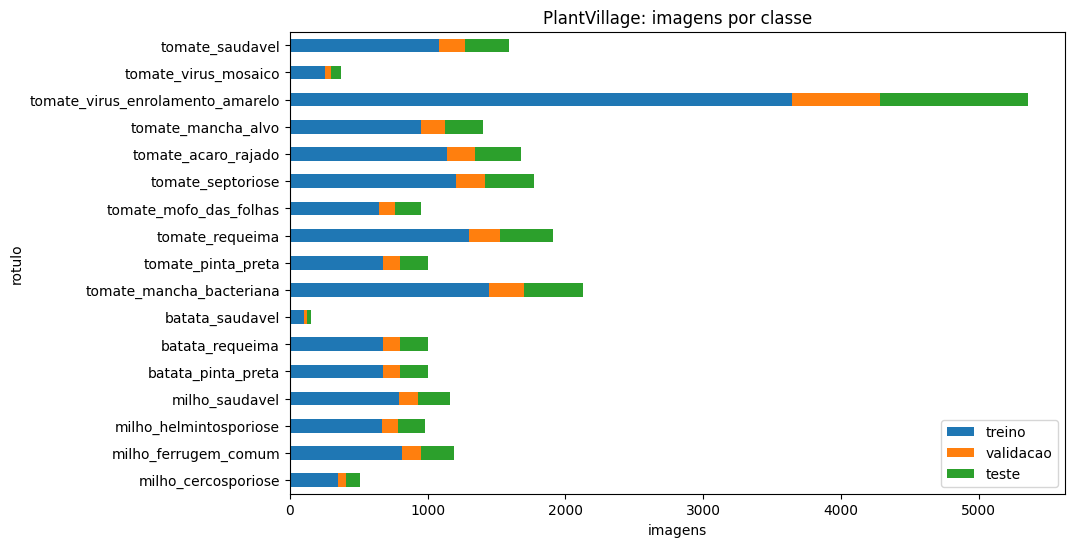

Maior classe: tomate_virus_enrolamento_amarelo (5357) | menor: batata_saudavel (152) | razão 35.2x


In [10]:
def tabela_contagem(partes):
    linhas = []
    for i, rotulo in enumerate(ROTULOS):
        linha = {"rotulo": rotulo, "cultura": CULTURAS[i]}
        for nome, amostras in partes.items():
            linha[nome] = sum(1 for a in amostras if a[1] == i)
        linhas.append(linha)
    return pd.DataFrame(linhas)


contagem_pv = tabela_contagem({"treino": pv_treino, "validacao": pv_val, "teste": pv_teste})
display(contagem_pv)

figura, eixo = plt.subplots(figsize=(10, 6))
contagem_pv.set_index("rotulo")[["treino", "validacao", "teste"]].plot.barh(
    stacked=True, ax=eixo
)
eixo.set_xlabel("imagens")
eixo.set_title("PlantVillage: imagens por classe")
salvar_figura(figura, "contagem_classes.png")

totais = contagem_pv[["treino", "validacao", "teste"]].sum(axis=1)
razao_desbalanceamento = float(totais.max() / max(totais.min(), 1))
print(
    f"Maior classe: {contagem_pv.loc[totais.idxmax(), 'rotulo']} ({totais.max()}) | "
    f"menor: {contagem_pv.loc[totais.idxmin(), 'rotulo']} ({totais.min()}) | "
    f"razão {razao_desbalanceamento:.1f}x"
)

O desbalanceamento é grande: o tomate tem muito mais imagens que a batata e algumas classes, como batata saudável, têm poucas centenas. Sem correção, o modelo aprenderia a favorecer as classes grandes. Por isso a perda é ponderada pelo inverso da frequência de cada classe (seção 3) e a métrica principal é o F1 macro, que dá o mesmo peso a todas as classes.

## 2. Pré-processamento

No treino, cada imagem sofre recortes, giros, inversões e variação de cor e brilho aleatórios. Isso simula fotos tiradas no campo com celular (enquadramento, ângulo e luz diferentes) e reduz o risco de o modelo decorar o fundo neutro do PlantVillage. Na validação, no teste e no serviço, a imagem só é redimensionada e cortada no centro, exatamente como faz `app/visao/classificador.py`. A normalização usa a média e o desvio do ImageNet porque os pesos pré-treinados foram aprendidos com ela.

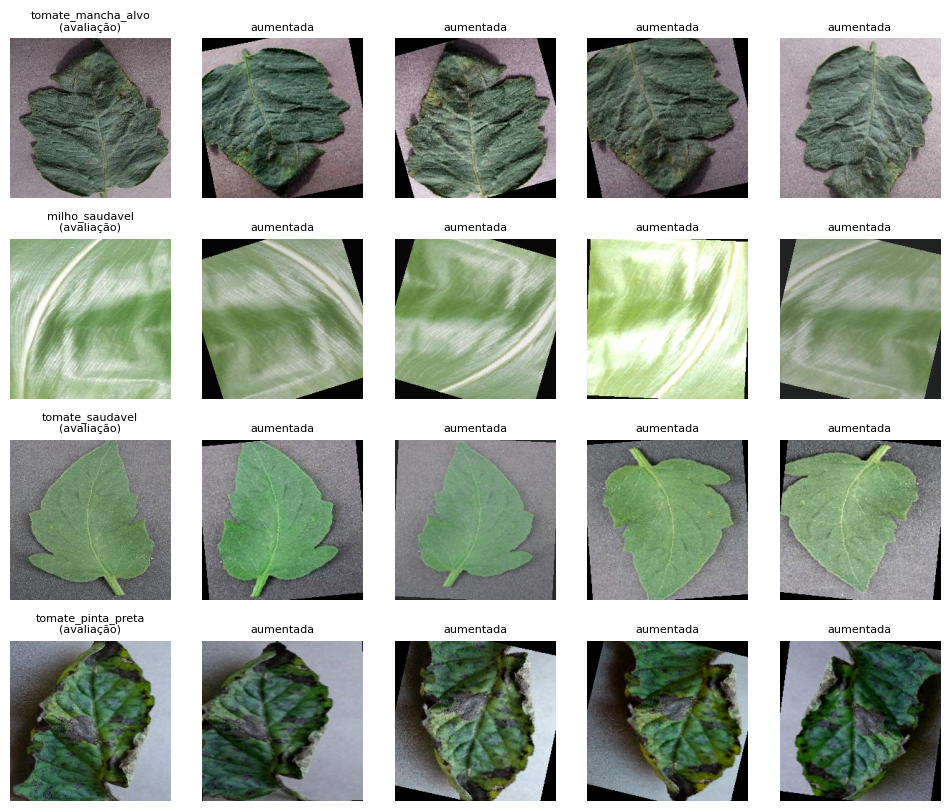

In [19]:
TRANSFORMACAO_TREINO = transforms.Compose(
    [
        transforms.RandomResizedCrop(TAMANHO_ENTRADA, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(20),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
        transforms.RandomGrayscale(p=0.05),
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, DESVIO),
    ]
)
TRANSFORMACAO_AVALIACAO = transforms.Compose(
    [
        transforms.Resize(REDIMENSIONAR),
        transforms.CenterCrop(TAMANHO_ENTRADA),
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, DESVIO),
    ]
)


class ImagensRotuladas(Dataset):
    def __init__(self, abrir, amostras, transformacao):
        self.abrir = abrir
        self.amostras = amostras
        self.transformacao = transformacao

    def __len__(self):
        return len(self.amostras)

    def __getitem__(self, i):
        ref, y, _ = self.amostras[i]
        return self.transformacao(self.abrir(ref)), y


def carregador(dataset, embaralhar=False):
    return DataLoader(
        dataset,
        batch_size=BATCH,
        shuffle=embaralhar,
        num_workers=TRABALHADORES,
        pin_memory=DISPOSITIVO.type == "cuda",
        persistent_workers=embaralhar and TRABALHADORES > 0,
    )


def desnormalizar(tensor):
    media = torch.tensor(MEDIA)[:, None, None]
    desvio = torch.tensor(DESVIO)[:, None, None]
    return (tensor * desvio + media).clamp(0, 1).permute(1, 2, 0).numpy()


exemplos = random.Random(SEED).sample(pv_treino, 4)
figura, eixos = plt.subplots(4, 5, figsize=(12, 10))
for linha, (ref, y, _) in enumerate(exemplos):
    original = PV["abrir"](ref)
    eixos[linha, 0].imshow(desnormalizar(TRANSFORMACAO_AVALIACAO(original)))
    eixos[linha, 0].set_title(f"{ROTULOS[y]}\n(avaliação)", fontsize=8)
    for coluna in range(1, 5):
        eixos[linha, coluna].imshow(desnormalizar(TRANSFORMACAO_TREINO(original)))
        eixos[linha, coluna].set_title("aumentada", fontsize=8)
for eixo in eixos.flat:
    eixo.axis("off")
salvar_figura(figura, "aumentos.png")

dl_pv_treino = carregador(ImagensRotuladas(PV["abrir"], pv_treino, TRANSFORMACAO_TREINO), True)
dl_pv_val = carregador(ImagensRotuladas(PV["abrir"], pv_val, TRANSFORMACAO_AVALIACAO))
dl_pv_teste = carregador(ImagensRotuladas(PV["abrir"], pv_teste, TRANSFORMACAO_AVALIACAO))

## 3. Experimento 1: MobileNetV3-Large x EfficientNet-B0

**Transfer learning.** Treinar uma rede do zero exigiria milhões de imagens. As duas redes já vêm treinadas no ImageNet e sabem reconhecer bordas, texturas e formas; trocamos só a última camada (1000 classes do ImageNet para as nossas 17) e reaproveitamos o resto.

**Duas fases.** Na fase 1 o corpo da rede fica congelado e só a camada nova aprende, com taxa de aprendizado maior, para ela não estragar os pesos pré-treinados com gradientes aleatórios do início. Na fase 2 a rede toda é liberada com taxa menor para se ajustar às folhas.

**Escolhas do treino.** AdamW (Adam com decaimento de peso separado); *label smoothing* 0.1 (o alvo vira 0.9 para a classe certa e o resto dividido entre as outras, o que evita confiança exagerada); perda ponderada pelo inverso da frequência; precisão mista (AMP) para treinar mais rápido na T4; parada antecipada quando o F1 macro da validação para de subir por 2 épocas.

**Por que essas duas redes.** As duas são feitas para rodar em CPU e celular. A MobileNetV3 prioriza velocidade; a EfficientNet-B0 costuma ser mais precisa, mas é mais lenta. O serviço roda em CPU, então a comparação olha qualidade e latência.

In [20]:
PESOS_PRE_TREINADOS = {
    "mobilenet_v3_large": (models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.IMAGENET1K_V2),
    "efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
}


def criar_modelo(arquitetura, pre_treinado=True):
    construtor, pesos = PESOS_PRE_TREINADOS[arquitetura]
    modelo = construtor(weights=pesos if pre_treinado else None)
    ultima = modelo.classifier[-1]
    modelo.classifier[-1] = nn.Linear(ultima.in_features, NUM_CLASSES)
    return modelo


def pesos_por_classe(amostras):
    contagem = np.bincount([a[1] for a in amostras], minlength=NUM_CLASSES).astype(float)
    pesos = np.where(contagem > 0, contagem.sum() / (NUM_CLASSES * np.maximum(contagem, 1)), 0.0)
    pesos = pesos / pesos[contagem > 0].mean()
    return torch.tensor(pesos, dtype=torch.float32)


def f1_macro(y, pred):
    return float(f1_score(y, pred, labels=sorted(set(y.tolist())), average="macro", zero_division=0))


@torch.no_grad()
def coletar_logits(modelo, loader):
    modelo.eval()
    saidas, alvos = [], []
    for x, y in loader:
        x = x.to(DISPOSITIVO, non_blocking=True)
        with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=USAR_AMP):
            logits = modelo(x)
        saidas.append(logits.float().cpu())
        alvos.append(y)
    return torch.cat(saidas), torch.cat(alvos)


def treinar_epoca(modelo, loader, criterio, otimizador, escalonador, escalador, congelado):
    modelo.train()
    if congelado:
        modelo.features.eval()
    total, quantidade = 0.0, 0
    for x, y in loader:
        x = x.to(DISPOSITIVO, non_blocking=True)
        y = y.to(DISPOSITIVO, non_blocking=True)
        otimizador.zero_grad(set_to_none=True)
        with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=USAR_AMP):
            perda = criterio(modelo(x), y)
        escalador.scale(perda).backward()
        escalador.step(otimizador)
        escalador.update()
        if escalonador is not None:
            escalonador.step()
        total += perda.item() * len(y)
        quantidade += len(y)
    return total / quantidade


def treinar_modelo(
    nome, modelo, dl_treino, dl_val, pesos, epocas_congelado, epocas_ajuste, lr_cabeca=1e-3, lr_ajuste=1e-4
):
    caminho = PASTA_CHECKPOINTS / f"{nome}.pt"
    caminho_historico = PASTA_CHECKPOINTS / f"{nome}_historico.json"
    modelo.to(DISPOSITIVO)
    if caminho.exists() and caminho_historico.exists():
        historico = json.loads(caminho_historico.read_text(encoding="utf-8"))
        if historico.get("concluido"):
            modelo.load_state_dict(torch.load(caminho, map_location=DISPOSITIVO, weights_only=True))
            print(f"{nome}: carregado do checkpoint (F1 macro validação {historico['melhorF1']:.4f})")
            return modelo, historico

    criterio = nn.CrossEntropyLoss(weight=pesos.to(DISPOSITIVO), label_smoothing=0.1)
    escalador = torch.amp.GradScaler("cuda", enabled=USAR_AMP)
    historico = {"epocas": [], "concluido": False, "melhorF1": -1.0}
    estado = {"sem_melhora": 0}

    def rodar_fase(fase, epocas, otimizador, escalonador, congelado):
        estado["sem_melhora"] = 0
        for epoca in range(1, epocas + 1):
            inicio = time.time()
            perda = treinar_epoca(
                modelo, dl_treino, criterio, otimizador, escalonador, escalador, congelado
            )
            logits, y = coletar_logits(modelo, dl_val)
            perda_val = F.cross_entropy(logits, y).item()
            f1 = f1_macro(y.numpy(), logits.argmax(1).numpy())
            historico["epocas"].append(
                {"fase": fase, "epoca": epoca, "perdaTreino": perda, "perdaVal": perda_val, "f1Val": f1}
            )
            print(
                f"{nome} | {fase} {epoca}/{epocas} | perda {perda:.4f} | perda val {perda_val:.4f} "
                f"| F1 val {f1:.4f} | {time.time() - inicio:.0f}s"
            )
            if f1 > historico["melhorF1"] + 1e-4:
                historico["melhorF1"] = f1
                estado["sem_melhora"] = 0
                torch.save(modelo.state_dict(), caminho)
            else:
                estado["sem_melhora"] += 1
            salvar_json(historico, caminho_historico)
            if fase == "ajuste" and estado["sem_melhora"] >= PACIENCIA:
                print(f"{nome}: parada antecipada")
                return

    # Fase 1: corpo congelado
    if epocas_congelado > 0:
        for parametro in modelo.features.parameters():
            parametro.requires_grad = False
        otimizador = torch.optim.AdamW(modelo.classifier.parameters(), lr=lr_cabeca, weight_decay=1e-4)
        rodar_fase("congelado", epocas_congelado, otimizador, None, True)

    # Fase 2: rede inteira
    for parametro in modelo.parameters():
        parametro.requires_grad = True
    otimizador = torch.optim.AdamW(
        [
            {"params": modelo.features.parameters(), "lr": lr_ajuste},
            {"params": modelo.classifier.parameters(), "lr": lr_ajuste * 3},
        ],
        weight_decay=1e-4,
    )
    escalonador = torch.optim.lr_scheduler.CosineAnnealingLR(
        otimizador, T_max=max(1, epocas_ajuste * len(dl_treino))
    )
    rodar_fase("ajuste", epocas_ajuste, otimizador, escalonador, False)

    modelo.load_state_dict(torch.load(caminho, map_location=DISPOSITIVO, weights_only=True))
    historico["concluido"] = True
    salvar_json(historico, caminho_historico)
    return modelo, historico

In [21]:
ARQUITETURAS = ["mobilenet_v3_large", "efficientnet_b0"]
pesos_pv = pesos_por_classe(pv_treino)
modelos_pv, historicos_pv = {}, {}
for arquitetura in ARQUITETURAS:
    fixar_seed()
    modelos_pv[arquitetura], historicos_pv[arquitetura] = treinar_modelo(
        f"pv_{arquitetura}",
        criar_modelo(arquitetura),
        dl_pv_treino,
        dl_pv_val,
        pesos_pv,
        EPOCAS_CONGELADO,
        EPOCAS_AJUSTE,
    )

pv_mobilenet_v3_large | congelado 1/2 | perda 1.4321 | perda val 0.6698 | F1 val 0.8546 | 181s
pv_mobilenet_v3_large | congelado 2/2 | perda 1.2105 | perda val 0.6284 | F1 val 0.8723 | 178s
pv_mobilenet_v3_large | ajuste 1/6 | perda 1.2051 | perda val 0.4123 | F1 val 0.9345 | 196s
pv_mobilenet_v3_large | ajuste 2/6 | perda 1.0500 | perda val 0.3901 | F1 val 0.9545 | 194s
pv_mobilenet_v3_large | ajuste 3/6 | perda 0.9990 | perda val 0.3456 | F1 val 0.9655 | 198s
pv_mobilenet_v3_large | ajuste 4/6 | perda 0.9790 | perda val 0.3474 | F1 val 0.9719 | 198s
pv_mobilenet_v3_large | ajuste 5/6 | perda 0.9718 | perda val 0.3351 | F1 val 0.9729 | 196s
pv_mobilenet_v3_large | ajuste 6/6 | perda 0.9670 | perda val 0.3330 | F1 val 0.9737 | 194s
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 116MB/s]


pv_efficientnet_b0 | congelado 1/2 | perda 1.6537 | perda val 0.7588 | F1 val 0.8171 | 186s
pv_efficientnet_b0 | congelado 2/2 | perda 1.3527 | perda val 0.6540 | F1 val 0.8479 | 182s
pv_efficientnet_b0 | ajuste 1/6 | perda 1.3155 | perda val 0.4493 | F1 val 0.9337 | 212s
pv_efficientnet_b0 | ajuste 2/6 | perda 1.0995 | perda val 0.4063 | F1 val 0.9482 | 210s
pv_efficientnet_b0 | ajuste 3/6 | perda 1.0513 | perda val 0.3650 | F1 val 0.9671 | 211s
pv_efficientnet_b0 | ajuste 4/6 | perda 1.0238 | perda val 0.3552 | F1 val 0.9646 | 211s
pv_efficientnet_b0 | ajuste 5/6 | perda 1.0113 | perda val 0.3480 | F1 val 0.9670 | 215s
pv_efficientnet_b0: parada antecipada


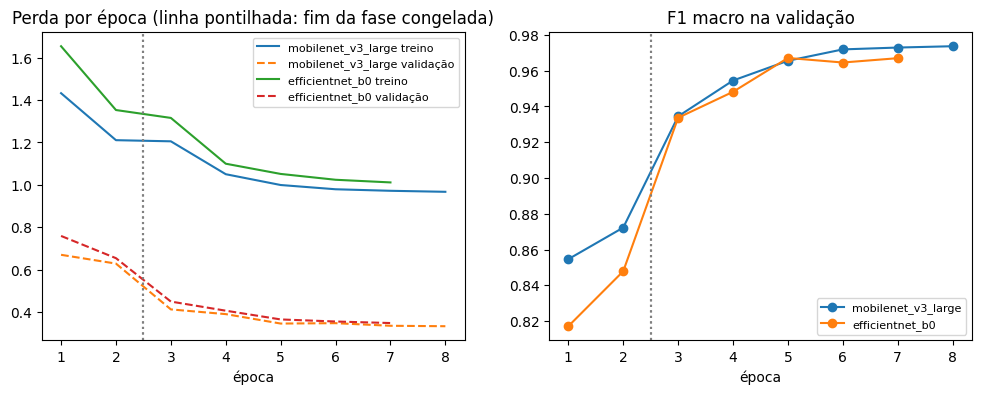

In [22]:
figura, eixos = plt.subplots(1, 2, figsize=(12, 4))
for arquitetura, historico in historicos_pv.items():
    epocas = historico["epocas"]
    x = range(1, len(epocas) + 1)
    eixos[0].plot(x, [e["perdaTreino"] for e in epocas], label=f"{arquitetura} treino")
    eixos[0].plot(x, [e["perdaVal"] for e in epocas], "--", label=f"{arquitetura} validação")
    eixos[1].plot(x, [e["f1Val"] for e in epocas], marker="o", label=arquitetura)
    fim_congelado = sum(1 for e in epocas if e["fase"] == "congelado")
    for eixo in eixos:
        eixo.axvline(fim_congelado + 0.5, color="gray", linestyle=":")
eixos[0].set_title("Perda por época (linha pontilhada: fim da fase congelada)")
eixos[1].set_title("F1 macro na validação")
for eixo in eixos:
    eixo.set_xlabel("época")
    eixo.legend(fontsize=8)
salvar_figura(figura, "curvas_treino.png")

## 4. Comparação no teste do PlantVillage

Além das métricas globais (17 classes), o notebook calcula as métricas **dentro da cultura**: o produtor informa se a foto é de milho, tomate ou batata, e o serviço escolhe a doença só entre as classes daquela cultura. Essa é a métrica que reflete o que a API devolve. A taxa de **cultura divergente** mostra quantas fotos corretas o serviço recusaria por achar que são de outra cultura (limite 0.7, igual ao do serviço).

In [23]:
def mascarar_cultura(logits, y):
    cultura_alvo = CULTURA_DA_CLASSE[y]
    mesma = CULTURA_DA_CLASSE[None, :] == cultura_alvo[:, None]
    return logits.masked_fill(~mesma, float("-inf"))


def calcular_metricas(logits, y, temperatura=1.0):
    y_np = y.numpy()
    escalado = logits / temperatura
    pred = escalado.argmax(1).numpy()
    presentes = sorted(set(y_np.tolist()))
    relatorio = classification_report(
        y_np,
        pred,
        labels=presentes,
        target_names=[ROTULOS[i] for i in presentes],
        output_dict=True,
        zero_division=0,
    )
    prob = escalado.softmax(1)
    soma_cultura = torch.stack([prob[:, INDICES_CULTURA[c]].sum(1) for c in CULTURA_LISTA], 1)
    detectada = soma_cultura.argmax(1)
    cultura_alvo = CULTURA_DA_CLASSE[y]
    divergente = (detectada != cultura_alvo) & (soma_cultura.max(1).values > LIMITE_DIVERGENCIA)

    prob_cultura = mascarar_cultura(escalado, y).softmax(1)
    pred_cultura = prob_cultura.argmax(1).numpy()
    top3 = prob_cultura.topk(3, dim=1).indices
    return {
        "imagens": int(len(y_np)),
        "global": {
            "acuracia": float(accuracy_score(y_np, pred)),
            "precisaoMacro": float(relatorio["macro avg"]["precision"]),
            "recallMacro": float(relatorio["macro avg"]["recall"]),
            "f1Macro": f1_macro(y_np, pred),
        },
        "dentroDaCultura": {
            "acuracia": float(accuracy_score(y_np, pred_cultura)),
            "acuraciaTop3": float((top3 == y[:, None]).any(1).float().mean()),
            "f1Macro": f1_macro(y_np, pred_cultura),
            "acertoDaCultura": float((detectada == cultura_alvo).float().mean()),
            "taxaCulturaDivergente": float(divergente.float().mean()),
        },
        "porClasse": {
            ROTULOS[i]: {
                "precisao": relatorio[ROTULOS[i]]["precision"],
                "recall": relatorio[ROTULOS[i]]["recall"],
                "f1": relatorio[ROTULOS[i]]["f1-score"],
                "suporte": int(relatorio[ROTULOS[i]]["support"]),
            }
            for i in presentes
        },
    }


def plotar_confusao(logits, y, titulo, arquivo, dentro_da_cultura=False):
    escalado = mascarar_cultura(logits, y) if dentro_da_cultura else logits
    pred = escalado.argmax(1).numpy()
    presentes = sorted(set(y.numpy().tolist()) | set(pred.tolist()))
    matriz = confusion_matrix(y.numpy(), pred, labels=presentes, normalize="true")
    figura, eixo = plt.subplots(figsize=(11, 9))
    imagem = eixo.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
    nomes = [ROTULOS[i] for i in presentes]
    eixo.set_xticks(range(len(nomes)), nomes, rotation=90, fontsize=8)
    eixo.set_yticks(range(len(nomes)), nomes, fontsize=8)
    for i in range(len(nomes)):
        for j in range(len(nomes)):
            if matriz[i, j] >= 0.01:
                cor = "white" if matriz[i, j] > 0.5 else "black"
                eixo.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontsize=6, color=cor)
    eixo.set_xlabel("previsto")
    eixo.set_ylabel("real")
    eixo.set_title(titulo)
    figura.colorbar(imagem, ax=eixo, fraction=0.046)
    salvar_figura(figura, arquivo)


def tamanho_mb(modelo):
    buffer = io.BytesIO()
    torch.save({k: v.cpu() for k, v in modelo.state_dict().items()}, buffer)
    return buffer.getbuffer().nbytes / 1e6


def latencia_cpu(arquitetura, modelo, repeticoes=50):
    copia = criar_modelo(arquitetura, pre_treinado=False)
    copia.load_state_dict({k: v.cpu() for k, v in modelo.state_dict().items()})
    copia.eval()
    threads = torch.get_num_threads()
    torch.set_num_threads(2)
    entrada = torch.randn(1, 3, TAMANHO_ENTRADA, TAMANHO_ENTRADA)
    tempos = []
    with torch.inference_mode():
        for _ in range(5):
            copia(entrada)
        for _ in range(repeticoes):
            inicio = time.perf_counter()
            copia(entrada)
            tempos.append((time.perf_counter() - inicio) * 1000)
    torch.set_num_threads(threads)
    return {"mediaMs": float(np.mean(tempos)), "p95Ms": float(np.percentile(tempos, 95)), "threads": 2}


mobilenet_v3_large
                                  precision    recall  f1-score   support

             milho_cercosporiose     0.8696    0.9709    0.9174       103
            milho_ferrugem_comum     1.0000    0.9874    0.9937       238
          milho_helmintosporiose     0.9786    0.9289    0.9531       197
                  milho_saudavel     0.9957    1.0000    0.9978       232
              batata_pinta_preta     0.9901    1.0000    0.9950       200
                 batata_requeima     0.9898    0.9750    0.9824       200
                 batata_saudavel     0.9091    1.0000    0.9524        30
        tomate_mancha_bacteriana     0.9530    1.0000    0.9759       426
              tomate_pinta_preta     0.9845    0.9500    0.9669       200
                 tomate_requeima     0.9741    0.9843    0.9792       382
          tomate_mofo_das_folhas     0.9948    1.0000    0.9974       190
               tomate_septoriose     1.0000    0.9774    0.9886       354
             toma

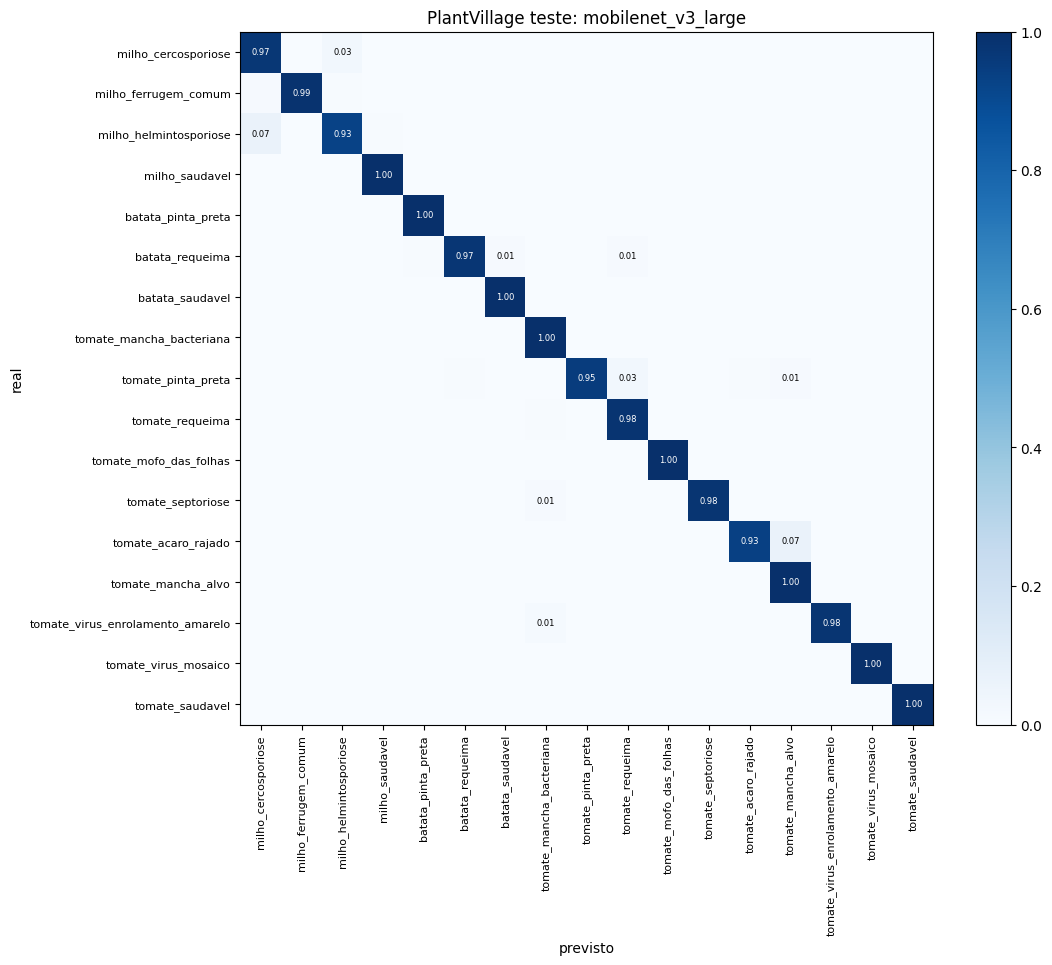


efficientnet_b0
                                  precision    recall  f1-score   support

             milho_cercosporiose     0.8448    0.9515    0.8950       103
            milho_ferrugem_comum     1.0000    0.9958    0.9979       238
          milho_helmintosporiose     0.9674    0.9036    0.9344       197
                  milho_saudavel     0.9872    1.0000    0.9936       232
              batata_pinta_preta     0.9950    1.0000    0.9975       200
                 batata_requeima     0.9848    0.9750    0.9799       200
                 batata_saudavel     0.7692    1.0000    0.8696        30
        tomate_mancha_bacteriana     0.9444    0.9977    0.9703       426
              tomate_pinta_preta     0.9842    0.9350    0.9590       200
                 tomate_requeima     0.9679    0.9476    0.9577       382
          tomate_mofo_das_folhas     0.9692    0.9947    0.9818       190
               tomate_septoriose     1.0000    0.9576    0.9784       354
             tomate_

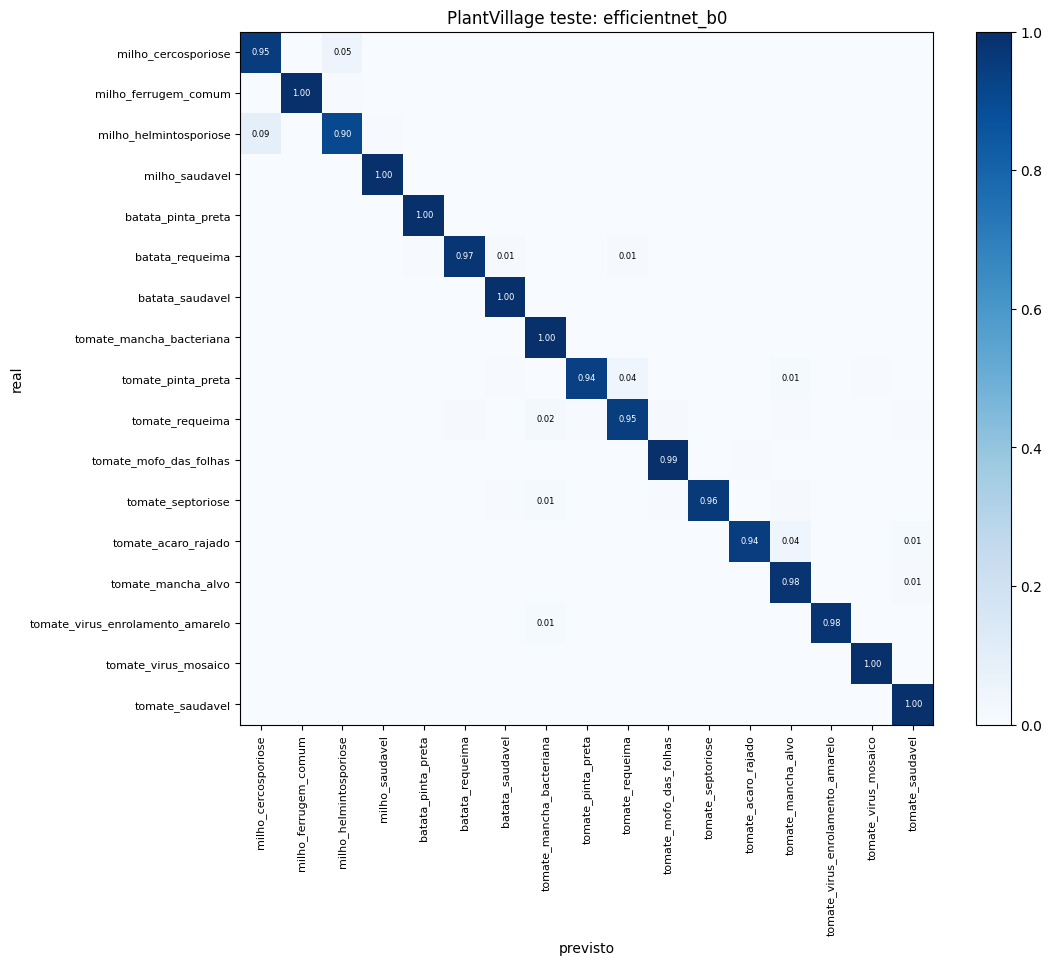

,acurácia,precisão macro,recall macro,F1 macro,F1 macro na cultura,cultura divergente,tamanho (MB),latência CPU (ms)
mobilenet_v3_large,0.9803,0.9725,0.9812,0.9763,0.9778,0.0002,17.0846,32.5773
efficientnet_b0,0.9741,0.9571,0.9742,0.9643,0.9711,0.0002,16.3945,42.4231


In [24]:
logits_teste_pv, y_teste_pv = {}, None
comparacao = {}
for arquitetura, modelo in modelos_pv.items():
    logits, y_teste_pv = coletar_logits(modelo, dl_pv_teste)
    logits_teste_pv[arquitetura] = logits
    comparacao[arquitetura] = {
        **calcular_metricas(logits, y_teste_pv),
        "tamanhoMb": tamanho_mb(modelo),
        "latenciaCpu": latencia_cpu(arquitetura, modelo),
        "melhorF1Validacao": historicos_pv[arquitetura]["melhorF1"],
    }
    salvar_json(comparacao[arquitetura], PASTA_AVALIACAO / f"plantvillage_{arquitetura}.json")
    print(f"\n{arquitetura}")
    print(
        classification_report(
            y_teste_pv.numpy(),
            logits.argmax(1).numpy(),
            labels=list(range(NUM_CLASSES)),
            target_names=ROTULOS,
            digits=4,
            zero_division=0,
        )
    )
    plotar_confusao(
        logits, y_teste_pv, f"PlantVillage teste: {arquitetura}", f"confusao_plantvillage_{arquitetura}.png"
    )

tabela_comparacao = pd.DataFrame(
    {
        a: {
            "acurácia": m["global"]["acuracia"],
            "precisão macro": m["global"]["precisaoMacro"],
            "recall macro": m["global"]["recallMacro"],
            "F1 macro": m["global"]["f1Macro"],
            "F1 macro na cultura": m["dentroDaCultura"]["f1Macro"],
            "cultura divergente": m["dentroDaCultura"]["taxaCulturaDivergente"],
            "tamanho (MB)": m["tamanhoMb"],
            "latência CPU (ms)": m["latenciaCpu"]["mediaMs"],
        }
        for a, m in comparacao.items()
    }
).T
display(tabela_comparacao.round(4))
tabela_comparacao.round(4).to_csv(PASTA_AVALIACAO / "comparacao.csv")

In [25]:
a, b = ARQUITETURAS
f1_a, f1_b = (comparacao[x]["global"]["f1Macro"] for x in (a, b))
lat_a, lat_b = (comparacao[x]["latenciaCpu"]["mediaMs"] for x in (a, b))
if abs(f1_a - f1_b) < 0.005:
    ARQ_ESCOLHIDA = a if lat_a <= lat_b else b
    motivo = (
        f"Os F1 macro ficaram praticamente iguais ({f1_a:.4f} x {f1_b:.4f}, diferença menor que 0.005). "
        f"Escolhida a {ARQ_ESCOLHIDA}, que é mais rápida em CPU ({min(lat_a, lat_b):.1f} ms x {max(lat_a, lat_b):.1f} ms)."
    )
else:
    ARQ_ESCOLHIDA = a if f1_a > f1_b else b
    outra = b if ARQ_ESCOLHIDA == a else a
    motivo = (
        f"A {ARQ_ESCOLHIDA} teve F1 macro {comparacao[ARQ_ESCOLHIDA]['global']['f1Macro']:.4f} contra "
        f"{comparacao[outra]['global']['f1Macro']:.4f} da {outra}, com latência em CPU de "
        f"{comparacao[ARQ_ESCOLHIDA]['latenciaCpu']['mediaMs']:.1f} ms x {comparacao[outra]['latenciaCpu']['mediaMs']:.1f} ms."
    )
salvar_json({"comparacao": comparacao, "escolhida": ARQ_ESCOLHIDA, "motivo": motivo}, PASTA_AVALIACAO / "comparacao.json")
display(Markdown(f"**Escolha:** {motivo}"))

**Escolha:** A mobilenet_v3_large teve F1 macro 0.9763 contra 0.9643 da efficientnet_b0, com latência em CPU de 32.6 ms x 42.4 ms.

## 5. Calibração da confiança

Redes neurais costumam ser confiantes demais: dizem 95% quando acertam 85% das vezes. Como a API Java usa a confiança para decidir se encaminha o caso ao agrônomo (limite 0.6), a confiança precisa significar o que diz.

**Temperature scaling.** Dividimos os logits por um número T aprendido na validação (T > 1 suaviza, T < 1 aguça). Não muda qual classe ganha, só o quanto o modelo diz ter certeza. O valor de T vai para `visao.json` e o serviço aplica a mesma divisão.

**ECE** (erro de calibração esperado): separa as previsões em faixas de confiança e mede a distância média entre a confiança e a acurácia real de cada faixa. Quanto menor, melhor. T é ajustado na validação e o ECE é medido no teste.

**Cobertura x acurácia.** Para cada limite de 0.3 a 0.95, mostra quantas fotos passariam (cobertura) e quanto o modelo acerta nelas. Ajuda a justificar o limite 0.6.

In [26]:
def ajustar_temperatura(logits, y):
    log_t = torch.zeros(1, requires_grad=True)
    otimizador = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

    def passo():
        otimizador.zero_grad()
        perda = F.cross_entropy(logits / log_t.exp(), y)
        perda.backward()
        return perda

    otimizador.step(passo)
    return float(log_t.exp())


def calcular_ece(prob, y, faixas=15):
    confianca, pred = prob.max(1)
    acerto = pred.eq(y).float()
    limites = torch.linspace(0, 1, faixas + 1)
    ece, detalhes = 0.0, []
    for inferior, superior in zip(limites[:-1], limites[1:], strict=True):
        selecao = (confianca > inferior) & (confianca <= superior)
        if selecao.any():
            conf_media = float(confianca[selecao].mean())
            acc_media = float(acerto[selecao].mean())
            peso = float(selecao.float().mean())
            ece += abs(acc_media - conf_media) * peso
            detalhes.append({"centro": float((inferior + superior) / 2), "confianca": conf_media, "acuracia": acc_media, "peso": peso})
    return ece, detalhes


def curva_cobertura(logits, y, temperatura):
    limites = np.round(np.arange(0.30, 0.951, 0.05), 2)
    linhas = []
    for modo, prob in (
        ("global", (logits / temperatura).softmax(1)),
        ("dentroDaCultura", mascarar_cultura(logits / temperatura, y).softmax(1)),
    ):
        confianca, pred = prob.max(1)
        acerto = pred.eq(y)
        for limite in limites:
            selecao = confianca >= float(limite)
            linhas.append(
                {
                    "modo": modo,
                    "limite": float(limite),
                    "cobertura": float(selecao.float().mean()),
                    "acuracia": float(acerto[selecao].float().mean()) if selecao.any() else None,
                }
            )
    return pd.DataFrame(linhas)


def avaliar_calibracao(nome, logits_val, y_val, logits_teste, y_teste):
    temperatura = ajustar_temperatura(logits_val, y_val)
    ece_antes, faixas_antes = calcular_ece(logits_teste.softmax(1), y_teste)
    ece_depois, faixas_depois = calcular_ece((logits_teste / temperatura).softmax(1), y_teste)
    nll_antes = F.cross_entropy(logits_teste, y_teste).item()
    nll_depois = F.cross_entropy(logits_teste / temperatura, y_teste).item()

    figura, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
    for eixo, faixas, titulo in (
        (eixos[0], faixas_antes, f"Antes (ECE {ece_antes:.4f})"),
        (eixos[1], faixas_depois, f"Depois, T = {temperatura:.3f} (ECE {ece_depois:.4f})"),
    ):
        eixo.bar([f["centro"] for f in faixas], [f["acuracia"] for f in faixas], width=1 / 15, edgecolor="black", alpha=0.7, label="acurácia")
        eixo.plot([0, 1], [0, 1], "r--", label="calibração perfeita")
        eixo.set_xlabel("confiança")
        eixo.set_ylabel("acurácia")
        eixo.set_title(titulo)
        eixo.legend()
    figura.suptitle(f"Diagrama de confiabilidade: {nome}")
    salvar_figura(figura, f"confiabilidade_{nome}.png")

    cobertura = curva_cobertura(logits_teste, y_teste, temperatura)
    figura, eixo = plt.subplots(figsize=(8, 4.5))
    for modo, grupo in cobertura.groupby("modo"):
        eixo.plot(grupo["limite"], grupo["cobertura"], marker="o", label=f"cobertura ({modo})")
        eixo.plot(grupo["limite"], grupo["acuracia"], marker="s", linestyle="--", label=f"acurácia ({modo})")
    eixo.axvline(LIMITE_CONFIANCA, color="red", linestyle=":", label=f"limite {LIMITE_CONFIANCA}")
    eixo.set_xlabel("limite de confiança")
    eixo.set_title(f"Cobertura x acurácia: {nome}")
    eixo.legend(fontsize=8)
    salvar_figura(figura, f"cobertura_{nome}.png")

    no_limite = cobertura[np.isclose(cobertura["limite"], LIMITE_CONFIANCA)].set_index("modo")
    resultado = {
        "temperatura": temperatura,
        "eceAntes": ece_antes,
        "eceDepois": ece_depois,
        "nllAntes": nll_antes,
        "nllDepois": nll_depois,
        "noLimite": no_limite[["cobertura", "acuracia"]].to_dict(orient="index"),
        "cobertura": cobertura.to_dict(orient="records"),
    }
    salvar_json(resultado, PASTA_AVALIACAO / f"calibracao_{nome}.json")
    return resultado

/tmp/ipykernel_823/880266248.py:12: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return float(log_t.exp())


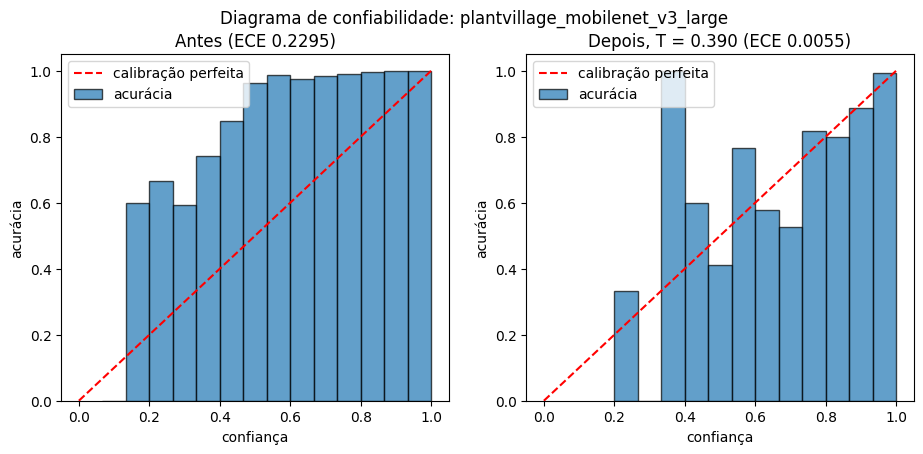

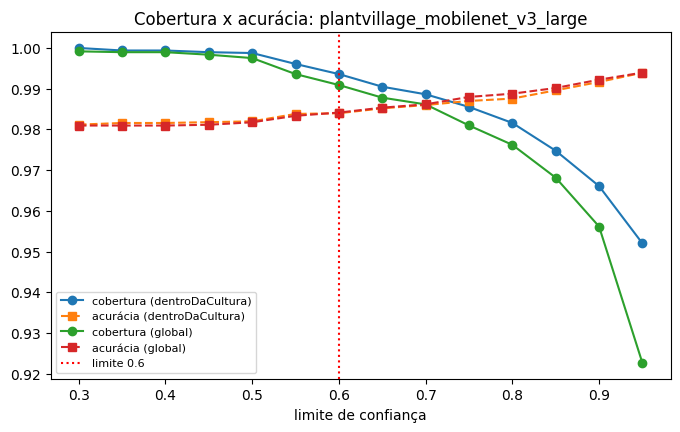

{'temperatura': 0.3897034227848053, 'eceAntes': 0.22954045596361322, 'eceDepois': 0.005502798094199507, 'nllAntes': 0.33282652497291565, 'nllDepois': 0.07474920153617859, 'noLimite': {'global': {'cobertura': 0.9908959269523621, 'acuracia': 0.984130322933197}, 'dentroDaCultura': {'cobertura': 0.9935857653617859, 'acuracia': 0.9839650392532349}}}


In [27]:
logits_val_pv, y_val_pv = coletar_logits(modelos_pv[ARQ_ESCOLHIDA], dl_pv_val)
calibracao_pv = avaliar_calibracao(
    f"plantvillage_{ARQ_ESCOLHIDA}", logits_val_pv, y_val_pv, logits_teste_pv[ARQ_ESCOLHIDA], y_teste_pv
)
print({k: v for k, v in calibracao_pv.items() if k != "cobertura"})

## 6. Experimento 2: fotos de campo (PlantDoc), sem ajuste

O PlantVillage tem fotos de laboratório, com uma folha sobre fundo neutro. O produtor vai fotografar no campo, com outras folhas, solo, sombra e mão aparecendo. O PlantDoc reúne fotos reais da internet com as mesmas doenças. Aqui o modelo escolhido é avaliado no PlantDoc **sem nenhum treino nele**, para medir a queda do laboratório para o campo.

Mapeamento das classes do PlantDoc para os nossos rótulos (a classe de ácaro do PlantDoc é ignorada porque tem só 2 imagens). As fotos de outras culturas são salvas para testar o portão de entrada do serviço.

In [28]:
MAPA_PLANTDOC = {
    "corngrayleafspot": "milho_cercosporiose",
    "cornleafblight": "milho_helmintosporiose",
    "cornrustleaf": "milho_ferrugem_comum",
    "potatoleafearlyblight": "batata_pinta_preta",
    "potatoleaflateblight": "batata_requeima",
    "potatoleaf": "batata_saudavel",
    "tomatoearlyblightleaf": "tomate_pinta_preta",
    "tomatoseptorialeafspot": "tomate_septoriose",
    "tomatoleaf": "tomate_saudavel",
    "tomatoleafbacterialspot": "tomate_mancha_bacteriana",
    "tomatoleaflateblight": "tomate_requeima",
    "tomatoleafmosaicvirus": "tomate_virus_mosaico",
    "tomatoleafyellowvirus": "tomate_virus_enrolamento_amarelo",
    "tomatomoldleaf": "tomate_mofo_das_folhas",
}
IGNORADAS_PLANTDOC = {"tomatotwospottedspidermitesleaf"}

PD = obter_fonte(
    [
        ("Hugging Face Project-AgML/plant_doc_classification", carregar_plantdoc_hf),
        ("GitHub pratikkayal/PlantDoc-Dataset", carregar_plantdoc_github),
    ]
)
mapa_pd = {
    k: INDICE[MAPA_PLANTDOC[normalizar(n)]] for k, n in enumerate(PD["nomes"]) if normalizar(n) in MAPA_PLANTDOC
}
sem_mapa = [
    n for n in PD["nomes"] if no_escopo(n) and normalizar(n) not in MAPA_PLANTDOC and normalizar(n) not in IGNORADAS_PLANTDOC
]
display(pd.DataFrame([{"PlantDoc": PD["nomes"][k], "rótulo Valence": ROTULOS[v]} for k, v in mapa_pd.items()]))
if sem_mapa:
    print(f"Atenção: classes do escopo sem mapeamento: {sem_mapa}")

pd_treino, pd_val, pd_teste, divisao_pd = separar_partes(PD["partes"], mapa_pd)
fora_pd = {k for k, n in enumerate(PD["nomes"]) if not no_escopo(n)}
pd_outras = [a for lista in PD["partes"].values() for a in lista if a[1] in fora_pd]
if MODO_RAPIDO:
    pd_treino = limitar(pd_treino, LIMITE_POR_CLASSE // 2)
    pd_val = limitar(pd_val, 4)
    pd_teste = limitar(pd_teste, 6)

DIVISAO["plantdoc"] = {"origem": PD["origem"], **divisao_pd}
print(DIVISAO["plantdoc"])
contagem_pd = tabela_contagem({"treino": pd_treino, "validacao": pd_val, "teste": pd_teste})
display(contagem_pd)
print(f"Imagens de outras culturas no PlantDoc: {len(pd_outras)}")

dl_pd_teste = carregador(ImagensRotuladas(PD["abrir"], pd_teste, TRANSFORMACAO_AVALIACAO))
dl_pd_val = carregador(ImagensRotuladas(PD["abrir"], pd_val, TRANSFORMACAO_AVALIACAO))
dl_pd_completo = carregador(
    ImagensRotuladas(PD["abrir"], pd_treino + pd_val + pd_teste, TRANSFORMACAO_AVALIACAO)
)

README.md:   0%|          | 0.00/2.99k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  470MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  524MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2569 [00:00<?, ? examples/s]

Fonte: Hugging Face Project-AgML/plant_doc_classification | partes: ['train'] | imagens: 2569


,PlantDoc,rótulo Valence
0,Corn Gray leaf spot,milho_cercosporiose
1,Corn leaf blight,milho_helmintosporiose
2,Corn rust leaf,milho_ferrugem_comum
3,Potato leaf early blight,batata_pinta_preta
4,Potato leaf late blight,batata_requeima
5,Tomato Early blight leaf,tomate_pinta_preta
6,Tomato Septoria leaf spot,tomate_septoriose
7,Tomato leaf,tomate_saudavel
8,Tomato leaf bacterial spot,tomate_mancha_bacteriana
9,Tomato leaf late blight,tomate_requeima


{'origem': 'Hugging Face Project-AgML/plant_doc_classification', 'teste': 'estratificada por classe', 'validacao': 'estratificada por classe'}


,rotulo,cultura,treino,validacao,teste
0,milho_cercosporiose,MILHO,46,8,14
1,milho_ferrugem_comum,MILHO,79,14,23
2,milho_helmintosporiose,MILHO,130,23,38
3,milho_saudavel,MILHO,0,0,0
4,batata_pinta_preta,BATATA,79,14,23
5,batata_requeima,BATATA,71,13,21
6,batata_saudavel,BATATA,0,0,0
7,tomate_mancha_bacteriana,TOMATE,75,13,22
8,tomate_pinta_preta,TOMATE,59,11,18
9,tomate_requeima,TOMATE,76,13,22


Imagens de outras culturas no PlantDoc: 1229


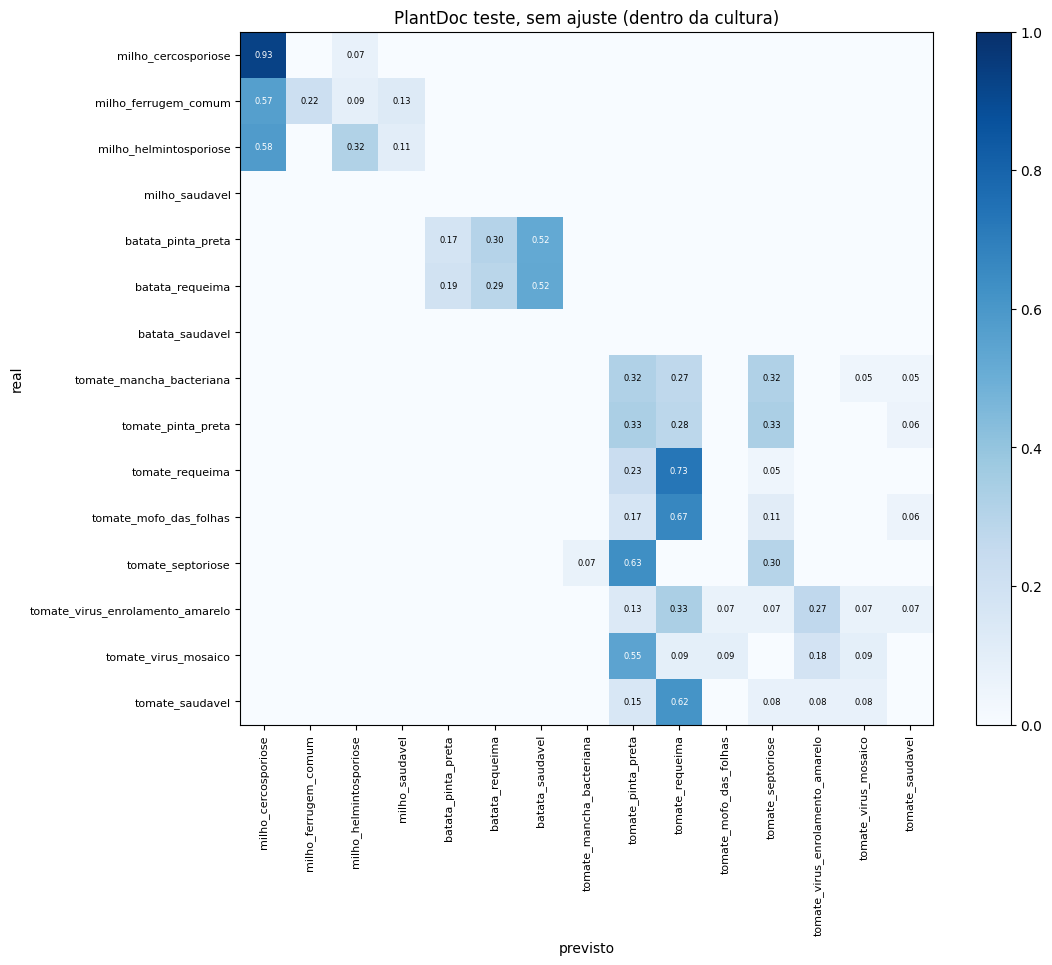

,PlantVillage teste,PlantDoc teste,PlantDoc todas
acuracia,0.9812,0.2836,0.3072
acuraciaTop3,0.9994,0.7500,0.7354
f1Macro,0.9778,0.2505,0.2767
acertoDaCultura,0.9992,0.7910,0.7892
taxaCulturaDivergente,0.0002,0.1343,0.1368


In [29]:
modelo_pv = modelos_pv[ARQ_ESCOLHIDA]
T_PV = calibracao_pv["temperatura"]
logits_pd_sem, y_pd_teste = coletar_logits(modelo_pv, dl_pd_teste)
logits_pd_completo, y_pd_completo = coletar_logits(modelo_pv, dl_pd_completo)
plantdoc_sem_ajuste = {
    "teste": calcular_metricas(logits_pd_sem, y_pd_teste, T_PV),
    "todasAsImagens": calcular_metricas(logits_pd_completo, y_pd_completo, T_PV),
}
salvar_json(plantdoc_sem_ajuste, PASTA_AVALIACAO / "plantdoc_sem_ajuste.json")
plotar_confusao(logits_pd_sem, y_pd_teste, "PlantDoc teste, sem ajuste (dentro da cultura)", "confusao_plantdoc_sem_ajuste.png", True)
display(
    pd.DataFrame(
        {
            "PlantVillage teste": comparacao[ARQ_ESCOLHIDA]["dentroDaCultura"],
            "PlantDoc teste": plantdoc_sem_ajuste["teste"]["dentroDaCultura"],
            "PlantDoc todas": plantdoc_sem_ajuste["todasAsImagens"]["dentroDaCultura"],
        }
    ).round(4)
)

### Amostras para avaliar o portão

O serviço tem um portão (CLIP) que recusa fotos que não são planta ou que são de outra cultura. Para medir esse portão, o notebook salva amostras redimensionadas: folhas das três culturas (devem passar) e folhas de outras culturas do PlantVillage e do PlantDoc (devem ser recusadas). Elas vão para `datasets/` no repositório, que não é versionada. Confira a grade abaixo: se aparecer alguma pessoa, apague a imagem antes de usar.

{'dentro_escopo': 150, 'fora_escopo_plantvillage': 150, 'fora_escopo_plantdoc': 150}


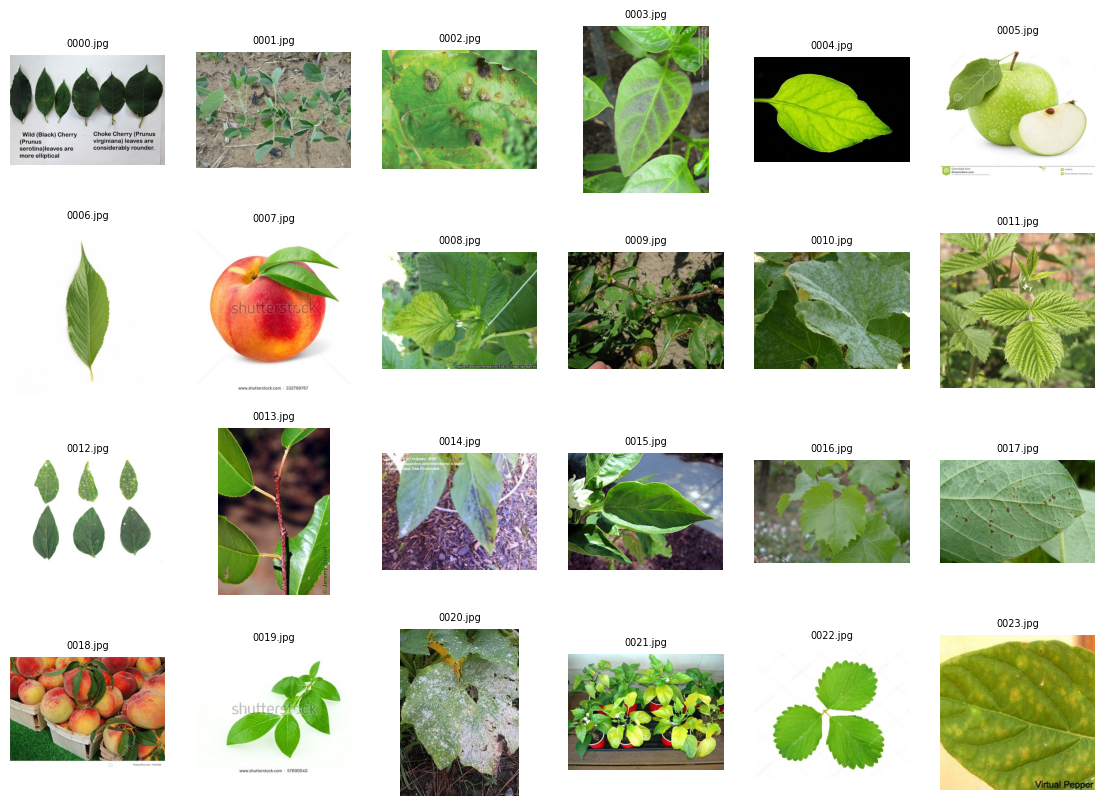

In [30]:
def exportar_amostras(abrir, amostras, pasta, quantidade):
    pasta.mkdir(parents=True, exist_ok=True)
    escolhidas = random.Random(SEED).sample(amostras, min(quantidade, len(amostras)))
    for i, (ref, _, _) in enumerate(escolhidas):
        imagem = abrir(ref)
        imagem.thumbnail((512, 512))
        imagem.save(pasta / f"{i:04d}.jpg", quality=90)
    return len(escolhidas)


amostras_portao = {
    "dentro_escopo": exportar_amostras(PV["abrir"], pv_teste, PASTA_AMOSTRAS / "dentro_escopo", AMOSTRAS_PORTAO),
    "fora_escopo_plantvillage": exportar_amostras(PV["abrir"], pv_outras, PASTA_AMOSTRAS / "fora_escopo_plantvillage", AMOSTRAS_PORTAO),
    "fora_escopo_plantdoc": exportar_amostras(PD["abrir"], pd_outras, PASTA_AMOSTRAS / "fora_escopo_plantdoc", AMOSTRAS_PORTAO),
}
salvar_json(
    {"quantidades": amostras_portao, "origens": {"plantvillage": PV["origem"], "plantdoc": PD["origem"]}},
    PASTA_AMOSTRAS / "origem.json",
)
print(amostras_portao)

arquivos = sorted((PASTA_AMOSTRAS / "fora_escopo_plantdoc").glob("*.jpg"))[:24]
if arquivos:
    figura, eixos = plt.subplots(4, 6, figsize=(14, 10))
    for eixo in eixos.flat:
        eixo.axis("off")
    for eixo, arquivo in zip(eixos.flat, arquivos, strict=False):
        eixo.imshow(Image.open(arquivo))
        eixo.set_title(arquivo.name, fontsize=7)
    plt.show()

## 7. Experimento 3: ajuste fino com fotos de campo

Partindo do modelo escolhido, treinamos mais algumas épocas com o PlantVillage junto com o treino do PlantDoc. Como o PlantDoc é bem menor, as imagens dele são repetidas para representar cerca de um quarto de cada época. A parada antecipada usa a validação do PlantDoc, porque o objetivo é melhorar no campo. Depois comparamos com o Experimento 2 nos dois testes.

**Regra de decisão para produção:** usar o modelo ajustado se o F1 macro na cultura subir pelo menos 0.01 no PlantDoc sem cair mais de 0.02 no PlantVillage.

PlantDoc repetido 6x | imagens por época: 21885
campo_mobilenet_v3_large | ajuste 1/4 | perda 1.2113 | perda val 1.4741 | F1 val 0.4868 | 362s
campo_mobilenet_v3_large | ajuste 2/4 | perda 1.0754 | perda val 1.5057 | F1 val 0.4794 | 358s
campo_mobilenet_v3_large | ajuste 3/4 | perda 1.0308 | perda val 1.5130 | F1 val 0.4795 | 359s
campo_mobilenet_v3_large: parada antecipada


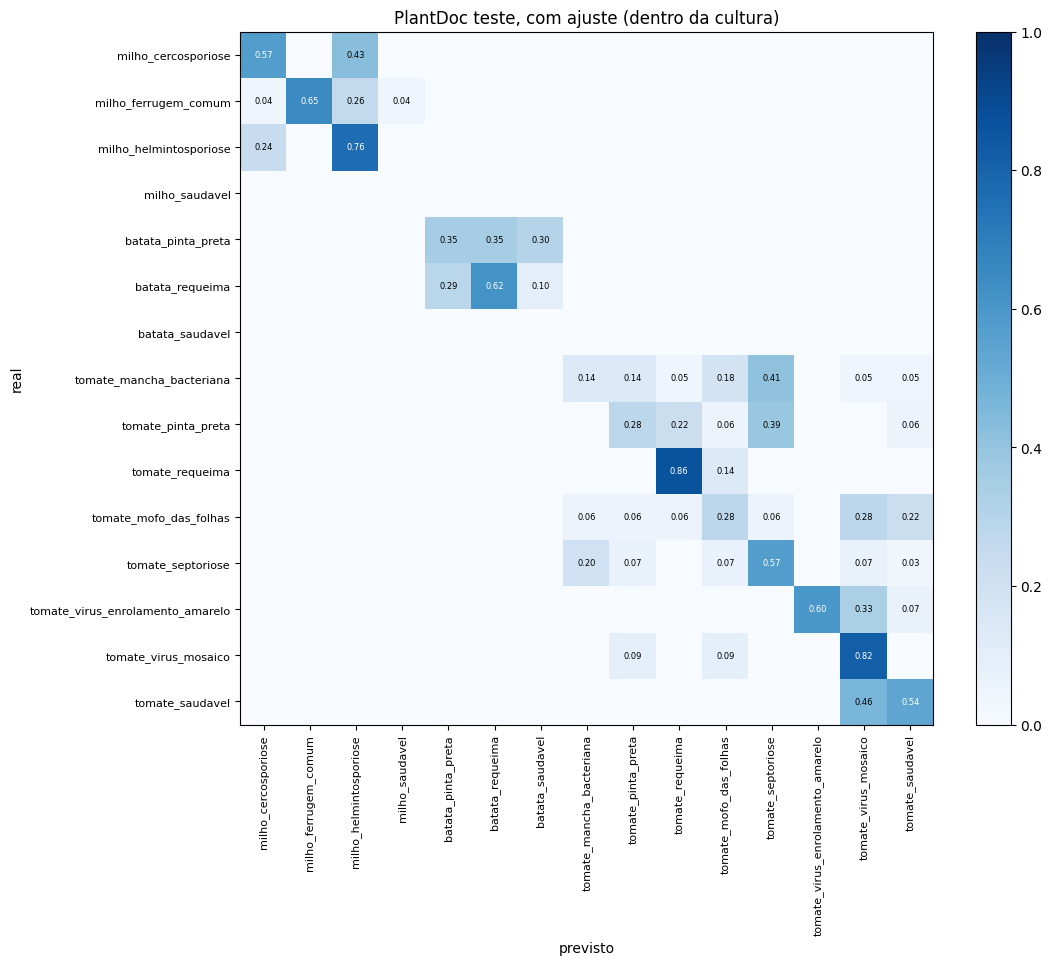

In [31]:
repeticoes = max(1, min(8, round(len(pv_treino) / (3 * max(1, len(pd_treino))))))
ds_campo = ConcatDataset(
    [ImagensRotuladas(PV["abrir"], pv_treino, TRANSFORMACAO_TREINO)]
    + [ImagensRotuladas(PD["abrir"], pd_treino, TRANSFORMACAO_TREINO)] * repeticoes
)
dl_campo = carregador(ds_campo, True)
print(f"PlantDoc repetido {repeticoes}x | imagens por época: {len(ds_campo)}")

fixar_seed()
modelo_campo = criar_modelo(ARQ_ESCOLHIDA, pre_treinado=False)
modelo_campo.load_state_dict(modelo_pv.state_dict())
modelo_campo, historico_campo = treinar_modelo(
    f"campo_{ARQ_ESCOLHIDA}",
    modelo_campo,
    dl_campo,
    dl_pd_val,
    pesos_por_classe(pv_treino + pd_treino * repeticoes),
    0,
    EPOCAS_CAMPO,
    lr_ajuste=5e-5,
)

logits_val_pv_campo, _ = coletar_logits(modelo_campo, dl_pv_val)
logits_val_pd_campo, y_val_pd = coletar_logits(modelo_campo, dl_pd_val)
logits_val_campo = torch.cat([logits_val_pv_campo, logits_val_pd_campo])
y_val_campo = torch.cat([y_val_pv, y_val_pd])
T_CAMPO = ajustar_temperatura(logits_val_campo, y_val_campo)

logits_pv_campo, _ = coletar_logits(modelo_campo, dl_pv_teste)
logits_pd_campo, _ = coletar_logits(modelo_campo, dl_pd_teste)
com_ajuste = {
    "temperatura": T_CAMPO,
    "plantvillageTeste": calcular_metricas(logits_pv_campo, y_teste_pv, T_CAMPO),
    "plantdocTeste": calcular_metricas(logits_pd_campo, y_pd_teste, T_CAMPO),
    "repeticoesPlantDoc": repeticoes,
}
salvar_json(com_ajuste, PASTA_AVALIACAO / "plantdoc_com_ajuste.json")
plotar_confusao(logits_pd_campo, y_pd_teste, "PlantDoc teste, com ajuste (dentro da cultura)", "confusao_plantdoc_com_ajuste.png", True)

,Exp. 2 (sem ajuste),Exp. 3 (com ajuste)
"F1 macro na cultura, PlantVillage",0.9778,0.9682
"F1 macro na cultura, PlantDoc",0.2505,0.5340
"acurácia na cultura, PlantDoc",0.2836,0.5485
"top 3 na cultura, PlantDoc",0.7500,0.9216
"cultura divergente, PlantDoc",0.1343,0.0709


**Decisão:** Vai para produção o modelo com ajuste fino: o F1 macro na cultura no PlantDoc subiu de 0.2505 para 0.5340 e no PlantVillage foi de 0.9778 para 0.9682.

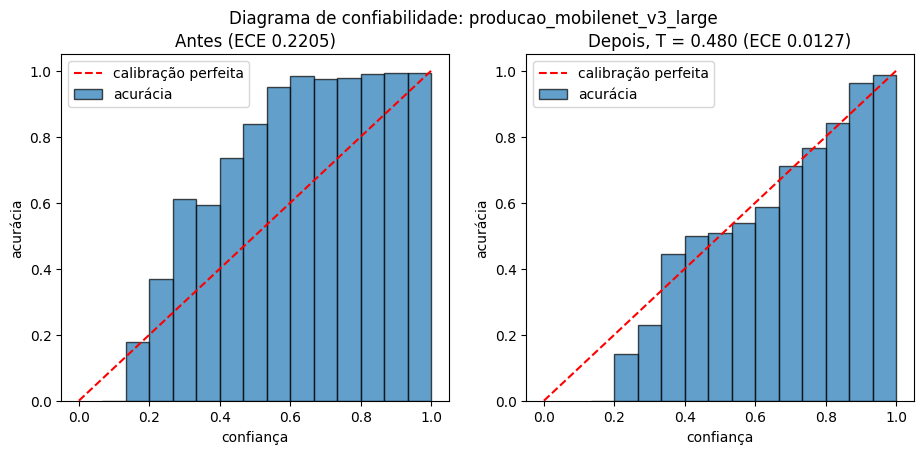

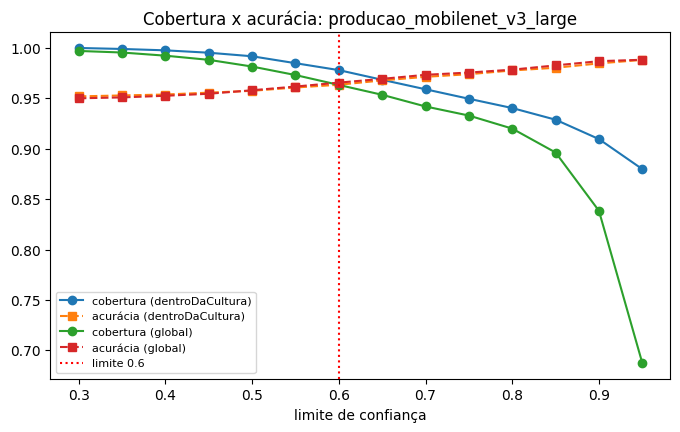

In [32]:
f1_pv_sem = comparacao[ARQ_ESCOLHIDA]["dentroDaCultura"]["f1Macro"]
f1_pv_com = com_ajuste["plantvillageTeste"]["dentroDaCultura"]["f1Macro"]
f1_pd_sem = plantdoc_sem_ajuste["teste"]["dentroDaCultura"]["f1Macro"]
f1_pd_com = com_ajuste["plantdocTeste"]["dentroDaCultura"]["f1Macro"]
tabela_campo = pd.DataFrame(
    {
        "Exp. 2 (sem ajuste)": {
            "F1 macro na cultura, PlantVillage": f1_pv_sem,
            "F1 macro na cultura, PlantDoc": f1_pd_sem,
            "acurácia na cultura, PlantDoc": plantdoc_sem_ajuste["teste"]["dentroDaCultura"]["acuracia"],
            "top 3 na cultura, PlantDoc": plantdoc_sem_ajuste["teste"]["dentroDaCultura"]["acuraciaTop3"],
            "cultura divergente, PlantDoc": plantdoc_sem_ajuste["teste"]["dentroDaCultura"]["taxaCulturaDivergente"],
        },
        "Exp. 3 (com ajuste)": {
            "F1 macro na cultura, PlantVillage": f1_pv_com,
            "F1 macro na cultura, PlantDoc": f1_pd_com,
            "acurácia na cultura, PlantDoc": com_ajuste["plantdocTeste"]["dentroDaCultura"]["acuracia"],
            "top 3 na cultura, PlantDoc": com_ajuste["plantdocTeste"]["dentroDaCultura"]["acuraciaTop3"],
            "cultura divergente, PlantDoc": com_ajuste["plantdocTeste"]["dentroDaCultura"]["taxaCulturaDivergente"],
        },
    }
)
display(tabela_campo.round(4))
tabela_campo.round(4).to_csv(PASTA_AVALIACAO / "campo.csv")

USAR_AJUSTE = (f1_pd_com - f1_pd_sem) >= 0.01 and (f1_pv_sem - f1_pv_com) <= 0.02
modelo_producao = modelo_campo if USAR_AJUSTE else modelo_pv
if USAR_AJUSTE:
    decisao = (
        f"Vai para produção o modelo com ajuste fino: o F1 macro na cultura no PlantDoc subiu de {f1_pd_sem:.4f} "
        f"para {f1_pd_com:.4f} e no PlantVillage foi de {f1_pv_sem:.4f} para {f1_pv_com:.4f}."
    )
else:
    decisao = (
        f"Vai para produção o modelo sem ajuste fino: no PlantDoc o F1 macro na cultura foi de {f1_pd_sem:.4f} "
        f"para {f1_pd_com:.4f} e no PlantVillage de {f1_pv_sem:.4f} para {f1_pv_com:.4f}, o que não cumpre a regra."
    )
display(Markdown(f"**Decisão:** {decisao}"))

if USAR_AJUSTE:
    calibracao_producao = avaliar_calibracao(
        f"producao_{ARQ_ESCOLHIDA}", logits_val_campo, y_val_campo,
        torch.cat([logits_pv_campo, logits_pd_campo]), torch.cat([y_teste_pv, y_pd_teste]),
    )
else:
    calibracao_producao = calibracao_pv
TEMPERATURA = calibracao_producao["temperatura"]

## 8. Grad-CAM: para onde o modelo olha

O Grad-CAM pega a última camada convolucional, calcula o quanto cada mapa de ativação influenciou a classe prevista (pela média do gradiente) e soma os mapas com esses pesos. O resultado é um mapa de calor sobre a imagem. Se o calor cai na lesão, o modelo aprendeu a doença; se cai no fundo ou na borda, aprendeu um atalho. Implementado com *hooks* do PyTorch, sem biblioteca extra.

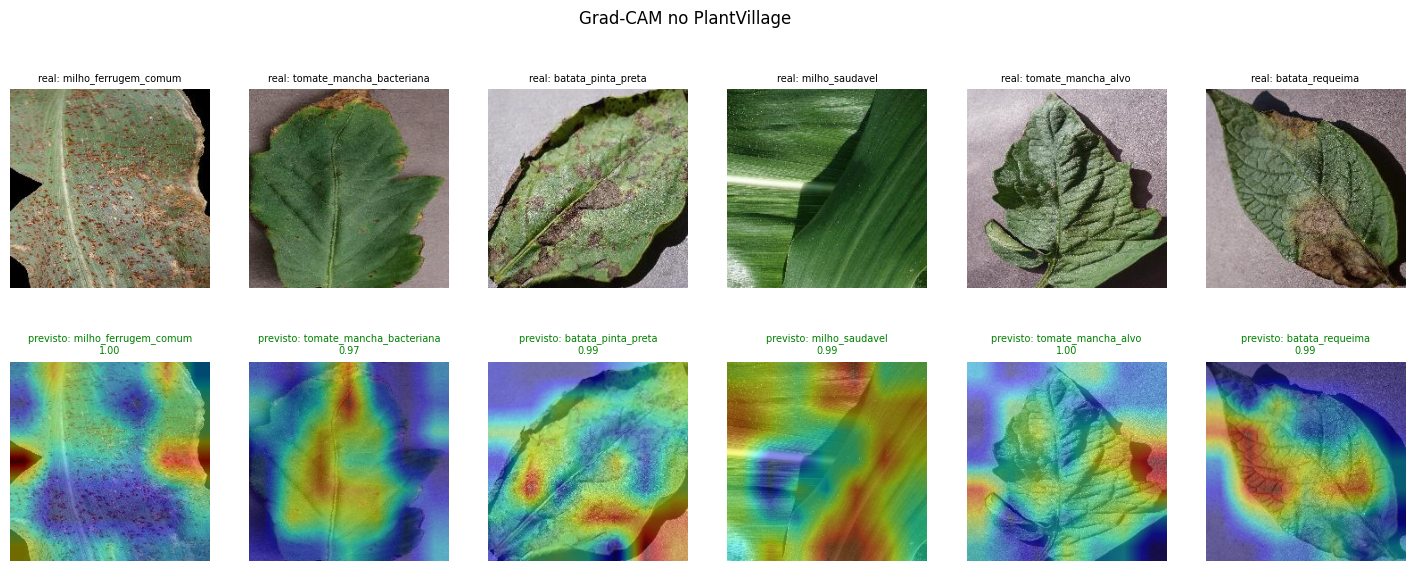

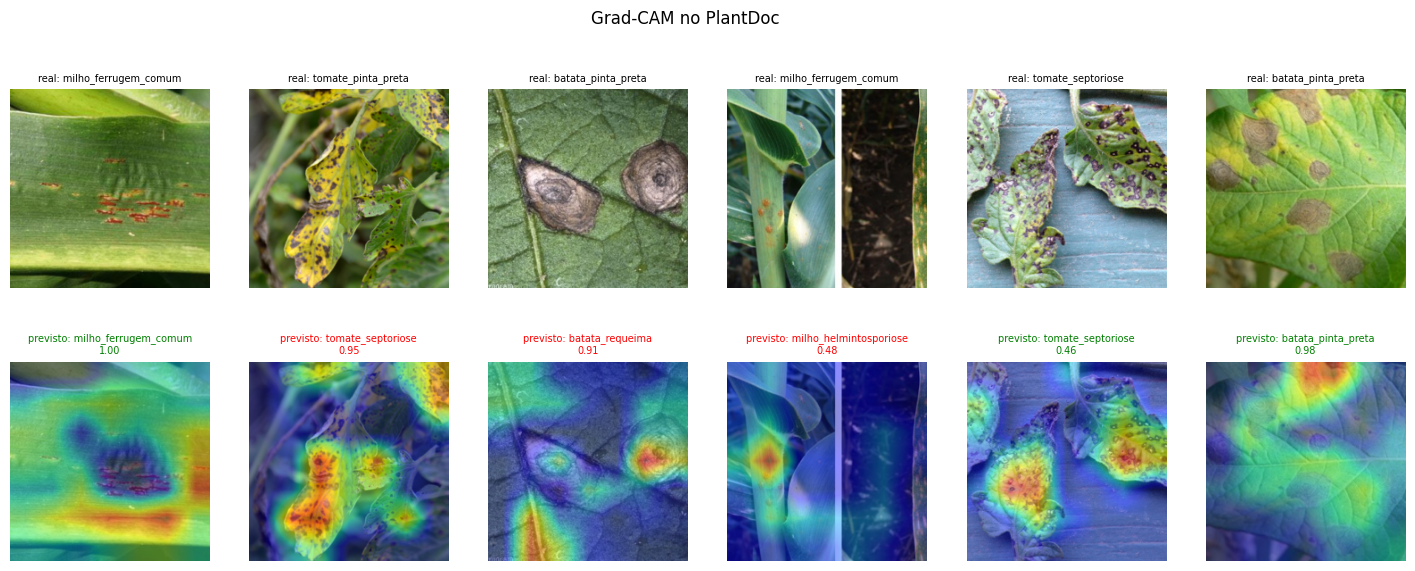

In [33]:
class GradCam:
    def __init__(self, modelo, camada):
        self.modelo = modelo
        self.ativacao = None
        self.gradiente = None
        self.gancho = camada.register_forward_hook(self._guardar)

    def _guardar(self, modulo, entrada, saida):
        self.ativacao = saida
        saida.register_hook(self._guardar_gradiente)

    def _guardar_gradiente(self, gradiente):
        self.gradiente = gradiente

    def __call__(self, entrada):
        self.modelo.eval()
        self.modelo.zero_grad(set_to_none=True)
        with torch.enable_grad():
            saida = self.modelo(entrada.to(DISPOSITIVO))
            classe = int(saida.argmax(1))
            saida[0, classe].backward()
        pesos = self.gradiente.mean(dim=(2, 3), keepdim=True)
        mapa = F.relu((pesos * self.ativacao).sum(1, keepdim=True))
        mapa = F.interpolate(mapa, size=entrada.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        mapa = (mapa - mapa.min()) / (mapa.max() - mapa.min() + 1e-8)
        confianca = float((saida / TEMPERATURA).softmax(1)[0, classe])
        return mapa.detach().cpu().numpy(), classe, confianca

    def remover(self):
        self.gancho.remove()


def escolher_por_cultura(amostras, quantidade):
    rng = random.Random(SEED)
    por_cultura = {c: [a for a in amostras if CULTURAS[a[1]] == c] for c in CULTURA_LISTA}
    escolhidas = []
    while len(escolhidas) < quantidade and any(por_cultura.values()):
        for cultura in CULTURA_LISTA:
            if por_cultura[cultura] and len(escolhidas) < quantidade:
                escolhidas.append(por_cultura[cultura].pop(rng.randrange(len(por_cultura[cultura]))))
    return escolhidas


def mostrar_gradcam(abrir, amostras, titulo, arquivo):
    modelo_producao.to(DISPOSITIVO).float()
    gradcam = GradCam(modelo_producao, modelo_producao.features[-1])
    figura, eixos = plt.subplots(2, len(amostras), figsize=(3 * len(amostras), 6.5))
    for coluna, (ref, y, _) in enumerate(amostras):
        entrada = TRANSFORMACAO_AVALIACAO(abrir(ref)).unsqueeze(0)
        mapa, classe, confianca = gradcam(entrada)
        imagem = desnormalizar(entrada[0])
        eixos[0, coluna].imshow(imagem)
        eixos[0, coluna].set_title(f"real: {ROTULOS[y]}", fontsize=7)
        eixos[1, coluna].imshow(imagem)
        eixos[1, coluna].imshow(mapa, cmap="jet", alpha=0.45)
        cor = "green" if classe == y else "red"
        eixos[1, coluna].set_title(f"previsto: {ROTULOS[classe]}\n{confianca:.2f}", fontsize=7, color=cor)
    for eixo in eixos.flat:
        eixo.axis("off")
    figura.suptitle(titulo)
    gradcam.remover()
    salvar_figura(figura, arquivo)


mostrar_gradcam(PV["abrir"], escolher_por_cultura(pv_teste, 6), "Grad-CAM no PlantVillage", "gradcam_plantvillage.png")
mostrar_gradcam(PD["abrir"], escolher_por_cultura(pd_teste, 6), "Grad-CAM no PlantDoc", "gradcam_plantdoc.png")

## 9. Exportação

`visao.pt` guarda só os pesos (`state_dict`), que o serviço carrega com `weights_only=True`, sem executar código do arquivo. `visao.json` traz tudo o que o serviço precisa para usar os pesos do jeito certo: arquitetura, ordem das classes, cultura de cada classe, normalização, tamanhos e temperatura. A célula seguinte recarrega os pesos do zero e repete a lógica do serviço para confirmar que o arquivo funciona.

In [34]:
estado_final = {k: v.detach().cpu() for k, v in modelo_producao.state_dict().items()}
torch.save(estado_final, PASTA_MODELOS / "visao.pt")

metricas_producao = com_ajuste if USAR_AJUSTE else {
    "plantvillageTeste": comparacao[ARQ_ESCOLHIDA],
    "plantdocTeste": plantdoc_sem_ajuste["teste"],
}
metadados = {
    "arquitetura": ARQ_ESCOLHIDA,
    "versaoPesos": PESOS_PRE_TREINADOS[ARQ_ESCOLHIDA][1].name,
    "classes": ROTULOS,
    "culturas": CULTURAS,
    "classesPlantVillage": [c[1] for c in CLASSES],
    "media": MEDIA,
    "desvio": DESVIO,
    "tamanhoEntrada": TAMANHO_ENTRADA,
    "redimensionar": REDIMENSIONAR,
    "temperatura": TEMPERATURA,
    "ajusteCampo": USAR_AJUSTE,
    "geradoEm": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "seed": SEED,
    "modoRapido": MODO_RAPIDO,
    "divisao": DIVISAO,
    "metricas": {
        "plantvillageF1MacroNaCultura": metricas_producao["plantvillageTeste"]["dentroDaCultura"]["f1Macro"],
        "plantvillageAcuracia": metricas_producao["plantvillageTeste"]["global"]["acuracia"],
        "plantdocF1MacroNaCultura": metricas_producao["plantdocTeste"]["dentroDaCultura"]["f1Macro"],
        "plantdocAcuraciaNaCultura": metricas_producao["plantdocTeste"]["dentroDaCultura"]["acuracia"],
        "eceDepois": calibracao_producao["eceDepois"],
        "latenciaCpuMs": comparacao[ARQ_ESCOLHIDA]["latenciaCpu"]["mediaMs"],
    },
}
salvar_json(metadados, PASTA_MODELOS / "visao.json")
print(json.dumps(metadados["metricas"], indent=2))

{
  "plantvillageF1MacroNaCultura": 0.968197204019905,
  "plantvillageAcuracia": 0.9724808607490172,
  "plantdocF1MacroNaCultura": 0.5339523870083801,
  "plantdocAcuraciaNaCultura": 0.5485074626865671,
  "eceDepois": 0.01266249690198314,
  "latenciaCpuMs": 32.5773464399208
}


In [35]:
meta = json.loads((PASTA_MODELOS / "visao.json").read_text(encoding="utf-8"))
recarregado = criar_modelo(meta["arquitetura"], pre_treinado=False)
recarregado.load_state_dict(torch.load(PASTA_MODELOS / "visao.pt", map_location="cpu", weights_only=True))
recarregado.eval()
assert len(meta["classes"]) == len(meta["culturas"]) == NUM_CLASSES

indices_cultura = {c: torch.tensor([i for i, cc in enumerate(meta["culturas"]) if cc == c]) for c in CULTURA_LISTA}
conferidas = 0
for ref, y, _ in pv_teste[:10]:
    entrada = TRANSFORMACAO_AVALIACAO(PV["abrir"](ref)).unsqueeze(0)
    with torch.inference_mode():
        logits = recarregado(entrada)[0] / meta["temperatura"]
    cultura = CULTURAS[y]
    na_cultura = logits[indices_cultura[cultura]].softmax(0)
    valores, posicoes = na_cultura.topk(min(3, len(indices_cultura[cultura])))
    classes = [(meta["classes"][int(indices_cultura[cultura][p])], round(float(v), 4)) for v, p in zip(valores, posicoes, strict=True)]
    assert all(meta["culturas"][meta["classes"].index(r)] == cultura for r, _ in classes)
    assert float(na_cultura.sum()) > 0.999
    conferidas += 1
print(f"Pesos recarregados e lógica do serviço conferida em {conferidas} imagens. Exemplo: {classes}")

Pesos recarregados e lógica do serviço conferida em 10 imagens. Exemplo: [('milho_ferrugem_comum', 0.9991), ('milho_helmintosporiose', 0.0005), ('milho_cercosporiose', 0.0004)]


## 10. Limitações observadas

O texto abaixo é gerado a partir dos números desta execução e salvo em `avaliacao/visao/limitacoes.md`, para ir direto para o relatório.

In [36]:
def piores_classes(metricas, quantidade=3, suporte_minimo=5):
    lista = [(r, m["f1"], m["suporte"]) for r, m in metricas["porClasse"].items() if m["suporte"] >= suporte_minimo]
    return sorted(lista, key=lambda x: x[1])[:quantidade]


teste_pd_final = metricas_producao["plantdocTeste"]
ausentes_pd = [r for i, r in enumerate(ROTULOS) if contagem_pd.loc[i, "teste"] == 0]
poucas_pd = [r for i, r in enumerate(ROTULOS) if 0 < contagem_pd.loc[i, "teste"] < 10]
no_limite = calibracao_producao["noLimite"].get("dentroDaCultura", {})
linhas = [
    "# Limitações do modelo de visão",
    "",
    f"- **Laboratório x campo.** F1 macro na cultura de {f1_pv_sem:.3f} no PlantVillage contra {f1_pd_sem:.3f} no PlantDoc sem ajuste. "
    f"A diferença de {f1_pv_sem - f1_pd_sem:.3f} mostra que fotos de laboratório superestimam o desempenho real.",
    f"- **Ajuste fino.** Com fotos de campo no treino, o F1 macro na cultura no PlantDoc foi para {f1_pd_com:.3f}. {decisao}",
    "- **Classes mais fracas no campo:** "
    + "; ".join(f"{r} (F1 {f:.2f}, {s} imagens)" for r, f, s in piores_classes(teste_pd_final)) + ".",
    f"- **Teste de campo pequeno.** O teste do PlantDoc tem {len(pd_teste)} imagens. "
    f"Classes sem imagem no teste: {', '.join(ausentes_pd) or 'nenhuma'}. Com menos de 10: {', '.join(poucas_pd) or 'nenhuma'}. "
    "Os números por classe nesses casos têm variação alta.",
    f"- **Divisão do PlantVillage:** {DIVISAO['plantvillage']['teste']} no teste e {DIVISAO['plantvillage']['validacao']} na validação. "
    + ("A mesma folha não aparece em treino e teste." if DIVISAO["plantvillage"]["colunaGrupo"] else
       "Sem identificador de folha, fotos da mesma folha podem estar em treino e teste, o que pode inflar o resultado de laboratório."),
    f"- **Calibração.** ECE de {calibracao_producao['eceAntes']:.3f} para {calibracao_producao['eceDepois']:.3f} com T = {TEMPERATURA:.3f}. "
    f"No limite {LIMITE_CONFIANCA}, dentro da cultura, passam {no_limite.get('cobertura', float('nan')):.1%} das fotos com acurácia de "
    f"{(no_limite.get('acuracia') or float('nan')):.1%}; o resto vai direto para o agrônomo.",
    f"- **Cultura divergente.** No PlantDoc, {teste_pd_final['dentroDaCultura']['taxaCulturaDivergente']:.1%} das fotos corretas seriam recusadas "
    f"como CULTURA_DIVERGENTE (limite {LIMITE_DIVERGENCIA}).",
    f"- **Latência.** {comparacao[ARQ_ESCOLHIDA]['latenciaCpu']['mediaMs']:.1f} ms por imagem em CPU do Colab com 2 threads, só a rede. "
    "No servidor da apresentação o valor muda e precisa ser medido de novo.",
    "- **Fora do modelo.** Pragas como cigarrinha-do-milho, lagarta-do-cartucho e traça-do-tomateiro não têm classe; "
    "o ácaro do PlantDoc foi ignorado por ter 2 imagens. Esses casos dependem do relato de sintomas (RAG) e do agrônomo.",
    "- **Uma folha por foto.** O modelo foi treinado com uma folha centralizada; fotos de planta inteira ou de várias folhas tendem a errar mais.",
    "- **Grad-CAM é qualitativo.** As figuras mostram 12 exemplos e servem para discussão, não como prova de que o modelo sempre olha a lesão.",
]
texto_limitacoes = "\n".join(linhas)
(PASTA_AVALIACAO / "limitacoes.md").write_text(texto_limitacoes, encoding="utf-8")
salvar_json(
    {
        "arquiteturaEscolhida": ARQ_ESCOLHIDA,
        "motivoEscolha": motivo,
        "ajusteCampo": USAR_AJUSTE,
        "decisao": decisao,
        "divisao": DIVISAO,
        "razaoDesbalanceamento": razao_desbalanceamento,
        "metricas": metadados["metricas"],
        "calibracao": {k: v for k, v in calibracao_producao.items() if k != "cobertura"},
    },
    PASTA_AVALIACAO / "resumo.json",
)
display(Markdown(texto_limitacoes))

# Limitações do modelo de visão

- **Laboratório x campo.** F1 macro na cultura de 0.978 no PlantVillage contra 0.250 no PlantDoc sem ajuste. A diferença de 0.727 mostra que fotos de laboratório superestimam o desempenho real.
- **Ajuste fino.** Com fotos de campo no treino, o F1 macro na cultura no PlantDoc foi para 0.534. Vai para produção o modelo com ajuste fino: o F1 macro na cultura no PlantDoc subiu de 0.2505 para 0.5340 e no PlantVillage foi de 0.9778 para 0.9682.
- **Classes mais fracas no campo:** tomate_mancha_bacteriana (F1 0.19, 22 imagens); tomate_pinta_preta (F1 0.24, 18 imagens); tomate_mofo_das_folhas (F1 0.24, 18 imagens).
- **Teste de campo pequeno.** O teste do PlantDoc tem 268 imagens. Classes sem imagem no teste: milho_saudavel, batata_saudavel, tomate_acaro_rajado, tomate_mancha_alvo. Com menos de 10: nenhuma. Os números por classe nesses casos têm variação alta.
- **Divisão do PlantVillage:** estratificada por classe no teste e estratificada por classe na validação. Sem identificador de folha, fotos da mesma folha podem estar em treino e teste, o que pode inflar o resultado de laboratório.
- **Calibração.** ECE de 0.220 para 0.013 com T = 0.480. No limite 0.6, dentro da cultura, passam 97.8% das fotos com acurácia de 96.4%; o resto vai direto para o agrônomo.
- **Cultura divergente.** No PlantDoc, 7.1% das fotos corretas seriam recusadas como CULTURA_DIVERGENTE (limite 0.7).
- **Latência.** 32.6 ms por imagem em CPU do Colab com 2 threads, só a rede. No servidor da apresentação o valor muda e precisa ser medido de novo.
- **Fora do modelo.** Pragas como cigarrinha-do-milho, lagarta-do-cartucho e traça-do-tomateiro não têm classe; o ácaro do PlantDoc foi ignorado por ter 2 imagens. Esses casos dependem do relato de sintomas (RAG) e do agrônomo.
- **Uma folha por foto.** O modelo foi treinado com uma folha centralizada; fotos de planta inteira ou de várias folhas tendem a errar mais.
- **Grad-CAM é qualitativo.** As figuras mostram 12 exemplos e servem para discussão, não como prova de que o modelo sempre olha a lesão.

## Download

Gera `valence_visao.zip`, guarda uma cópia no Drive e baixa no navegador. No repositório: `modelos/visao.pt` e `modelos/visao.json` em `modelos/`, o conteúdo de `avaliacao/visao/` em `avaliacao/visao/` e `amostras_portao/` em `datasets/amostras_portao/` (não versionada).

In [37]:
arquivo_zip = shutil.make_archive("valence_visao", "zip", SAIDA)
if NO_COLAB:
    shutil.copy(arquivo_zip, PASTA_CHECKPOINTS / "valence_visao.zip")
    from google.colab import files

    files.download(arquivo_zip)
print(f"Pronto: {arquivo_zip}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Pronto: /content/valence_visao.zip
